# NB\_C04: Diffusion MRI -- Microstructure, Connectivity, and Tractography

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/glioma-brain-digital-twin-public/blob/main/notebooks/NB_C04_Diffusion_MRI_Tractography.ipynb)

**Capstone Notebook Series** -- Glioma Brain Digital Twin Project  
**Workshop:** Mathematical Challenges in Brain Mechanics ([CAS 2025/2026](https://cas-nor.no/project/mathematical-challenges-brain-mechanics)), 9-11 March 2026, Hotel Finse 1222 [[link](https://cas-nor.no/events/mathematical-challenges-brain-mechanics-workshop)]  
**Patient:** sub-PAT16 (anaplastic astrocytoma WHO II--III, fronto-temporal) from the OpenNeuro repository [[preop](https://openneuro.org/datasets/ds001226/versions/5.0.0)] [[postop](https://openneuro.org/datasets/ds002080/versions/4.0.0)]<br>
**Date:** 7 March 2026 <br>
**Creator:** Arvid Lundervold w/ Cursor 2.6.13 and Opus 4.6

---

## Objectives

- Understand the physical principles of diffusion-weighted MRI
- Derive and interpret DTI scalar maps (ADC/MD, FA, RD, AD)
- Load pipeline-computed DTI maps and structural connectivity matrices
- Appreciate the role of tractography (whole-brain fibre tracking) in the digital twin
- Use freeview for interactive DTI and tractography visualisation

**Prerequisites:** [NB\_C01](NB_C01_Digital_Twin_Concept_and_Data.ipynb), [NB\_C03](NB_C03_Structural_MRI_Segmentation.ipynb)  
**Next:** [NB\_C05](NB_C05_Resting_State_fMRI.ipynb) (resting-state fMRI)

---
## 1. Diffusion MRI Principles

### The physics of water diffusion in tissue

Diffusion MRI (dMRI) measures the random thermal motion (Brownian motion)
of water molecules *in vivo*. In free water, diffusion is **isotropic**
(equal in all directions). In brain tissue, microstructural barriers --
particularly myelinated axon membranes -- restrict diffusion, making it
**anisotropic** (direction-dependent).

### The Stejskal-Tanner equation

The signal attenuation in a diffusion-weighted image follows:

$$S(\mathbf{g}) = S_0 \, \exp\!\left(-b \, \mathbf{g}^T \mathbf{D} \, \mathbf{g}\right)$$

where:
- $S_0$ is the signal without diffusion weighting ($b = 0$)
- $b$ is the diffusion weighting factor ($s/mm^2$), controlled by gradient
  strength and timing
- $\mathbf{g}$ is the unit gradient direction vector
- $\mathbf{D}$ is the **diffusion tensor** ($3\times3$ symmetric positive-definite matrix)

### The diffusion tensor

$$\mathbf{D} = \begin{pmatrix} D_{xx} & D_{xy} & D_{xz} \\ D_{xy} & D_{yy} & D_{yz} \\ D_{xz} & D_{yz} & D_{zz} \end{pmatrix} = \mathbf{V} \boldsymbol{\Lambda} \mathbf{V}^T$$

Eigenvalue decomposition yields:
- $\lambda_1 \geq \lambda_2 \geq \lambda_3$ -- eigenvalues (diffusivities along principal axes)
- $\mathbf{v}_1, \mathbf{v}_2, \mathbf{v}_3$ -- eigenvectors (principal diffusion directions)

### Derived scalar maps

| Metric | Formula | Interpretation |
|--------|---------|----------------|
| **ADC / MD** | $\text{MD} = \frac{\lambda_1 + \lambda_2 + \lambda_3}{3}$ | Average diffusivity; sensitive to cellularity, oedema |
| **FA** | $\text{FA} = \sqrt{\frac{3}{2}} \cdot \frac{\sqrt{(\lambda_1 - \text{MD})^2 + (\lambda_2 - \text{MD})^2 + (\lambda_3 - \text{MD})^2}}{\sqrt{\lambda_1^2 + \lambda_2^2 + \lambda_3^2}}$ | Degree of anisotropy [0,1]; WM integrity |
| **AD** | $\text{AD} = \lambda_1$ | Diffusivity along the principal axis; axonal integrity |
| **RD** | $\text{RD} = \frac{\lambda_2 + \lambda_3}{2}$ | Perpendicular diffusivity; myelin integrity |

### Clinical interpretation

| Tissue | FA | MD | AD | RD |
|--------|----|----|-------|-------|
| Healthy WM | 0.4--0.8 | Low (~0.7e-3) | High | Low |
| Gray matter | 0.1--0.3 | Moderate (~0.9e-3) | Moderate | Moderate |
| Tumour core | <0.3 | High (>1.5e-3) | Low | High |
| Oedema | Low | Very high | Low | High |
| CSF | ≈0 | Very high (≈3e-3) | ≈ MD | ≈ MD |

---
## 2. Preprocessing Pipeline

The DWI data was preprocessed using **QSIPrep** followed by **MRtrix3**:

1. **QSIPrep**: susceptibility distortion correction (using AP+PA acquisitions),
   eddy current correction, motion correction, gradient re-orientation
2. **MRtrix3 DTI fit**: tensor estimation from preprocessed DWI
3. **MRtrix3 CSD**: constrained spherical deconvolution for fibre orientation
   distributions (superior to DTI in crossing fibre regions)
4. **Tractography**: anatomically-constrained tractography (ACT) with SIFT2
   streamline weighting
5. **Registration**: DTI maps co-registered to T1w space using
   `register_to_t1w.sh`

### Application to the PAT16 multi-shell acquisition

The DWI data for sub-PAT16 (pre-op) was acquired on a **3 T Siemens TrioTim**
scanner using a multi-shell diffusion scheme with the following parameters:

| Parameter | Value |
|-----------|-------|
| Scanner | 3 T Siemens TrioTim |
| TE / TR | 110 ms / 8.7 s |
| Flip angle | 90° |
| Acceleration (GRAPPA) | ×2 |
| Phase-encoding directions | AP + PA (for susceptibility distortion correction) |

**Shell structure** (after QSIPrep preprocessing):

| Shell ($b$, s/mm²) | Volumes | Role |
|---------------------|---------|------|
| 0 | 8 | Non-diffusion-weighted reference ($S_0$) |
| 700 | 16 | Low weighting — sensitive to slow diffusion / large structures |
| 1200 | 30 | Intermediate — good SNR for tensor estimation |
| 2800 | 50 | High weighting — sensitive to fast / restricted diffusion |
| **Total** | **104** | |

#### From raw DWI to the diffusion tensor

1. **Signal model.**  For each voxel and each diffusion-weighted volume $k$
   with gradient direction $\mathbf{g}_k$ and b-value $b_k$, the
   Stejskal–Tanner equation predicts:

$$S_k = S_0 \, \exp\!\bigl(-b_k \, \mathbf{g}_k^T \mathbf{D} \, \mathbf{g}_k\bigr)$$

2. **Estimating $S_0$.**  The non-diffusion-weighted reference signal $S_0$
   is obtained from the $b = 0$ volumes (8 in our acquisition, interleaved
   throughout the scan).  For each voxel, $S_0$ is estimated as the
   **mean** across these volumes:

$$\hat{S}_0(\mathbf{x}) = \frac{1}{N_{b=0}} \sum_{i=1}^{N_{b=0}} S_{b=0}^{(i)}(\mathbf{x})$$

   Averaging over multiple $b = 0$ acquisitions improves the signal-to-noise
   ratio of the reference and mitigates the effect of scanner drift, since
   the 8 volumes are distributed across the full acquisition rather than
   acquired in a single block.

3. **Linearisation.**  Taking the logarithm of $S_k / \hat{S}_0$ converts
   the problem to a linear system in the six independent elements of the
   symmetric tensor $\mathbf{D}$:

$$\ln\!\left(\frac{S_k}{S_0}\right) = -b_k \, \mathbf{g}_k^T \mathbf{D} \, \mathbf{g}_k$$

   Writing the six unknowns as
   $\mathbf{d} = (D_{xx},\, D_{yy},\, D_{zz},\, D_{xy},\, D_{xz},\, D_{yz})^T$,
   each volume yields one equation $\mathbf{a}_k^T \mathbf{d} = y_k$ where
   $y_k = -\frac{1}{b_k}\ln(S_k / \hat{S}_0)$ and $\mathbf{a}_k$ encodes
   the gradient direction products.

4. **Least-squares fit.**  With $N_\text{DW}$ diffusion-weighted volumes
   (96 in our case), the over-determined system
   $\mathbf{A}\,\mathbf{d} = \mathbf{y}$ is solved by **weighted least
   squares** (WLS), where the weights account for the signal-dependent noise
   variance introduced by the log-transform:

$$\hat{\mathbf{d}} = (\mathbf{A}^T \mathbf{W} \mathbf{A})^{-1} \mathbf{A}^T \mathbf{W} \mathbf{y}$$

5. **Eigendecomposition.**  The fitted $3\times 3$ tensor $\mathbf{D}$ is
   diagonalised to yield eigenvalues $\lambda_1 \geq \lambda_2 \geq \lambda_3$
   and eigenvectors $\mathbf{v}_1, \mathbf{v}_2, \mathbf{v}_3$.

6. **Scalar maps.**  The eigenvalues are combined into the clinically
   interpretable maps shown above (FA, MD, AD, RD).

#### Why multi-shell matters

The classical DTI model (single tensor) requires only a **single non-zero
$b$-value** (typically $b \approx 1000$ s/mm²) with ≥ 6 gradient directions.
Our multi-shell data ($b = 700, 1200, 2800$) is far richer:

- **For DTI**, the lower shells ($b = 700, 1200$) provide excellent SNR for
  robust tensor estimation, while the $b = 2800$ shell is less ideal for the
  single-tensor model (signal attenuation becomes non-mono-exponential at
  high $b$).  MRtrix3's `dwi2tensor` handles this by performing a WLS fit
  across all shells.
- **Beyond DTI**, the high $b$-value shell enables
  **constrained spherical deconvolution** (CSD), which resolves crossing
  fibre populations that the single-tensor model cannot represent.  This is
  critical for tractography (Section 5).
- The multiple $b = 0$ volumes (8 in total, interleaved throughout the
  acquisition) improve the estimate of $S_0$ and help detect/correct
  scanner drift.

In [77]:
import pandas as pd

# Paths to the preprocessed bval / bvec files (QSIPrep, ACPC space)
bval_path = DERIV_PROJ / 'qsiprep' / 'sub-PAT16' / 'ses-preop' / 'dwi' / \
            'sub-PAT16_ses-preop_space-ACPC_desc-preproc_dwi.bval'
bvec_path = DERIV_PROJ / 'qsiprep' / 'sub-PAT16' / 'ses-preop' / 'dwi' / \
            'sub-PAT16_ses-preop_space-ACPC_desc-preproc_dwi.bvec'

b_values = np.loadtxt(str(bval_path)).astype(int)
g_vectors = np.loadtxt(str(bvec_path))            # shape (3, N)

N = len(b_values)
df_dwi = pd.DataFrame({
    'k':     np.arange(1, N + 1),
    'b_k':   b_values,
    'g_x':   np.round(g_vectors[0], 4),
    'g_y':   np.round(g_vectors[1], 4),
    'g_z':   np.round(g_vectors[2], 4),
})
df_dwi['|g|'] = np.round(np.sqrt(
    g_vectors[0]**2 + g_vectors[1]**2 + g_vectors[2]**2), 4)
df_dwi = df_dwi.set_index('k')

shell_counts = df_dwi['b_k'].value_counts().sort_index()
print(f'Multi-shell DWI scheme  —  {N} volumes total')
print(f'Shells: {", ".join(f"b={b} ({n} vol)" for b, n in shell_counts.items())}')
print()

with pd.option_context('display.max_rows', None,
                        'display.float_format', '{:.4f}'.format):
    display(df_dwi)

Multi-shell DWI scheme  —  104 volumes total
Shells: b=0 (8 vol), b=700 (16 vol), b=1200 (30 vol), b=2800 (50 vol)



,b_k,g_x,g_y,g_z,|g|
k,,,,,
1,0,-0.0000,-0.0000,0.0000,0.0000
2,0,-0.0000,-0.0000,0.0000,0.0000
3,0,-0.0000,-0.0000,0.0000,0.0000
4,0,-0.0000,-0.0000,0.0000,0.0000
5,700,-0.7117,0.5885,0.3835,1.0000
6,2800,0.0978,-0.9943,0.0427,1.0000
7,1200,-0.7615,-0.5800,0.2893,1.0000
8,2800,0.8323,0.1598,0.5308,1.0000
9,1200,-0.4428,0.2014,-0.8737,1.0000


In [78]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.io import loadmat
import nibabel as nib
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# ── Colab / local environment setup ─────────────────────────────────────────
if 'google.colab' in sys.modules:
    REPO_ROOT = Path('/content/glioma-brain-digital-twin')
    if not REPO_ROOT.exists():
        import subprocess
        _clone_result = subprocess.run(
            ['git', 'clone', '--depth', '1',
             'https://github.com/arvidl/glioma-brain-digital-twin-public.git',
             str(REPO_ROOT)],
            capture_output=True, text=True)
        if _clone_result.returncode != 0:
            raise RuntimeError(f'git clone failed: {_clone_result.stderr}')
    !pip install -q -r {REPO_ROOT}/environment/requirements-colab.txt
    if not (REPO_ROOT / 'data' / 'BIDS_preop_postop' / 'sub-PAT16').exists():
        !python {REPO_ROOT}/data/download_data.py --capstone
    os.chdir(REPO_ROOT)
else:
    _cwd = Path.cwd().resolve()
    REPO_ROOT = _cwd if (_cwd / 'pyproject.toml').exists() else _cwd.parent

sys.path.insert(0, str(REPO_ROOT))

BIDS_ROOT   = REPO_ROOT / 'data' / 'BIDS_preop_postop'
DERIV_PROJ  = REPO_ROOT / 'derivatives'
REG_DIR     = DERIV_PROJ / 'registered_t1w' / 'sub-PAT16'
LONG_DIR    = REG_DIR / 'longitudinal'
CONN_DIR    = DERIV_PROJ / 'connectivity' / 'sub-PAT16'
TVB_DIR     = BIDS_ROOT / 'derivatives' / 'TVB' / 'sub-PAT16'
FIG_DIR     = Path('figures') / 'capstone'
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({'figure.dpi': 150, 'savefig.dpi': 300,
                     'font.size': 10, 'axes.titlesize': 12,
                     'figure.facecolor': 'white'})

DK68_NAMES_LH = [
    'bankssts','caudalanteriorcingulate','caudalmiddlefrontal',
    'cuneus','entorhinal','fusiform','inferiorparietal',
    'inferiortemporal','isthmuscingulate','lateraloccipital',
    'lateralorbitofrontal','lingual','medialorbitofrontal',
    'middletemporal','parahippocampal','paracentral',
    'parsopercularis','parsorbitalis','parstriangularis',
    'pericalcarine','postcentral','posteriorcingulate',
    'precentral','precuneus','rostralanteriorcingulate',
    'rostralmiddlefrontal','superiorfrontal','superiorparietal',
    'superiortemporal','supramarginal','frontalpole',
    'temporalpole','transversetemporal','insula']
DK68_NAMES = [f'lh-{n}' for n in DK68_NAMES_LH] + \
             [f'rh-{n}' for n in DK68_NAMES_LH]
N_REGIONS = 68

print(f'Repository root: {REPO_ROOT}')

Repository root: <REPO_ROOT>


---
## 3. DTI Scalar Maps

The pipeline-computed DTI maps (FA, MD, AD, RD) are loaded in T1w space.
These maps reveal the microstructural properties of the brain tissue.

FA: loaded from fa_space-T1w.nii.gz, shape=(160, 256, 256)
MD: loaded from md_space-T1w.nii.gz, shape=(160, 256, 256)
AD: loaded from ad_space-T1w.nii.gz, shape=(160, 256, 256)
RD: loaded from rd_space-T1w.nii.gz, shape=(160, 256, 256)
T1w: loaded from sub-PAT16_ses-preop_desc-preproc_T1w.nii.gz, shape=(160, 256, 256)
b=0: loaded from sub-PAT16_ses-preop_space-ACPC_dwiref.nii.gz, reoriented to RAS, shape=(161, 197, 171)
Tumour mask loaded — best axial slice at z=138


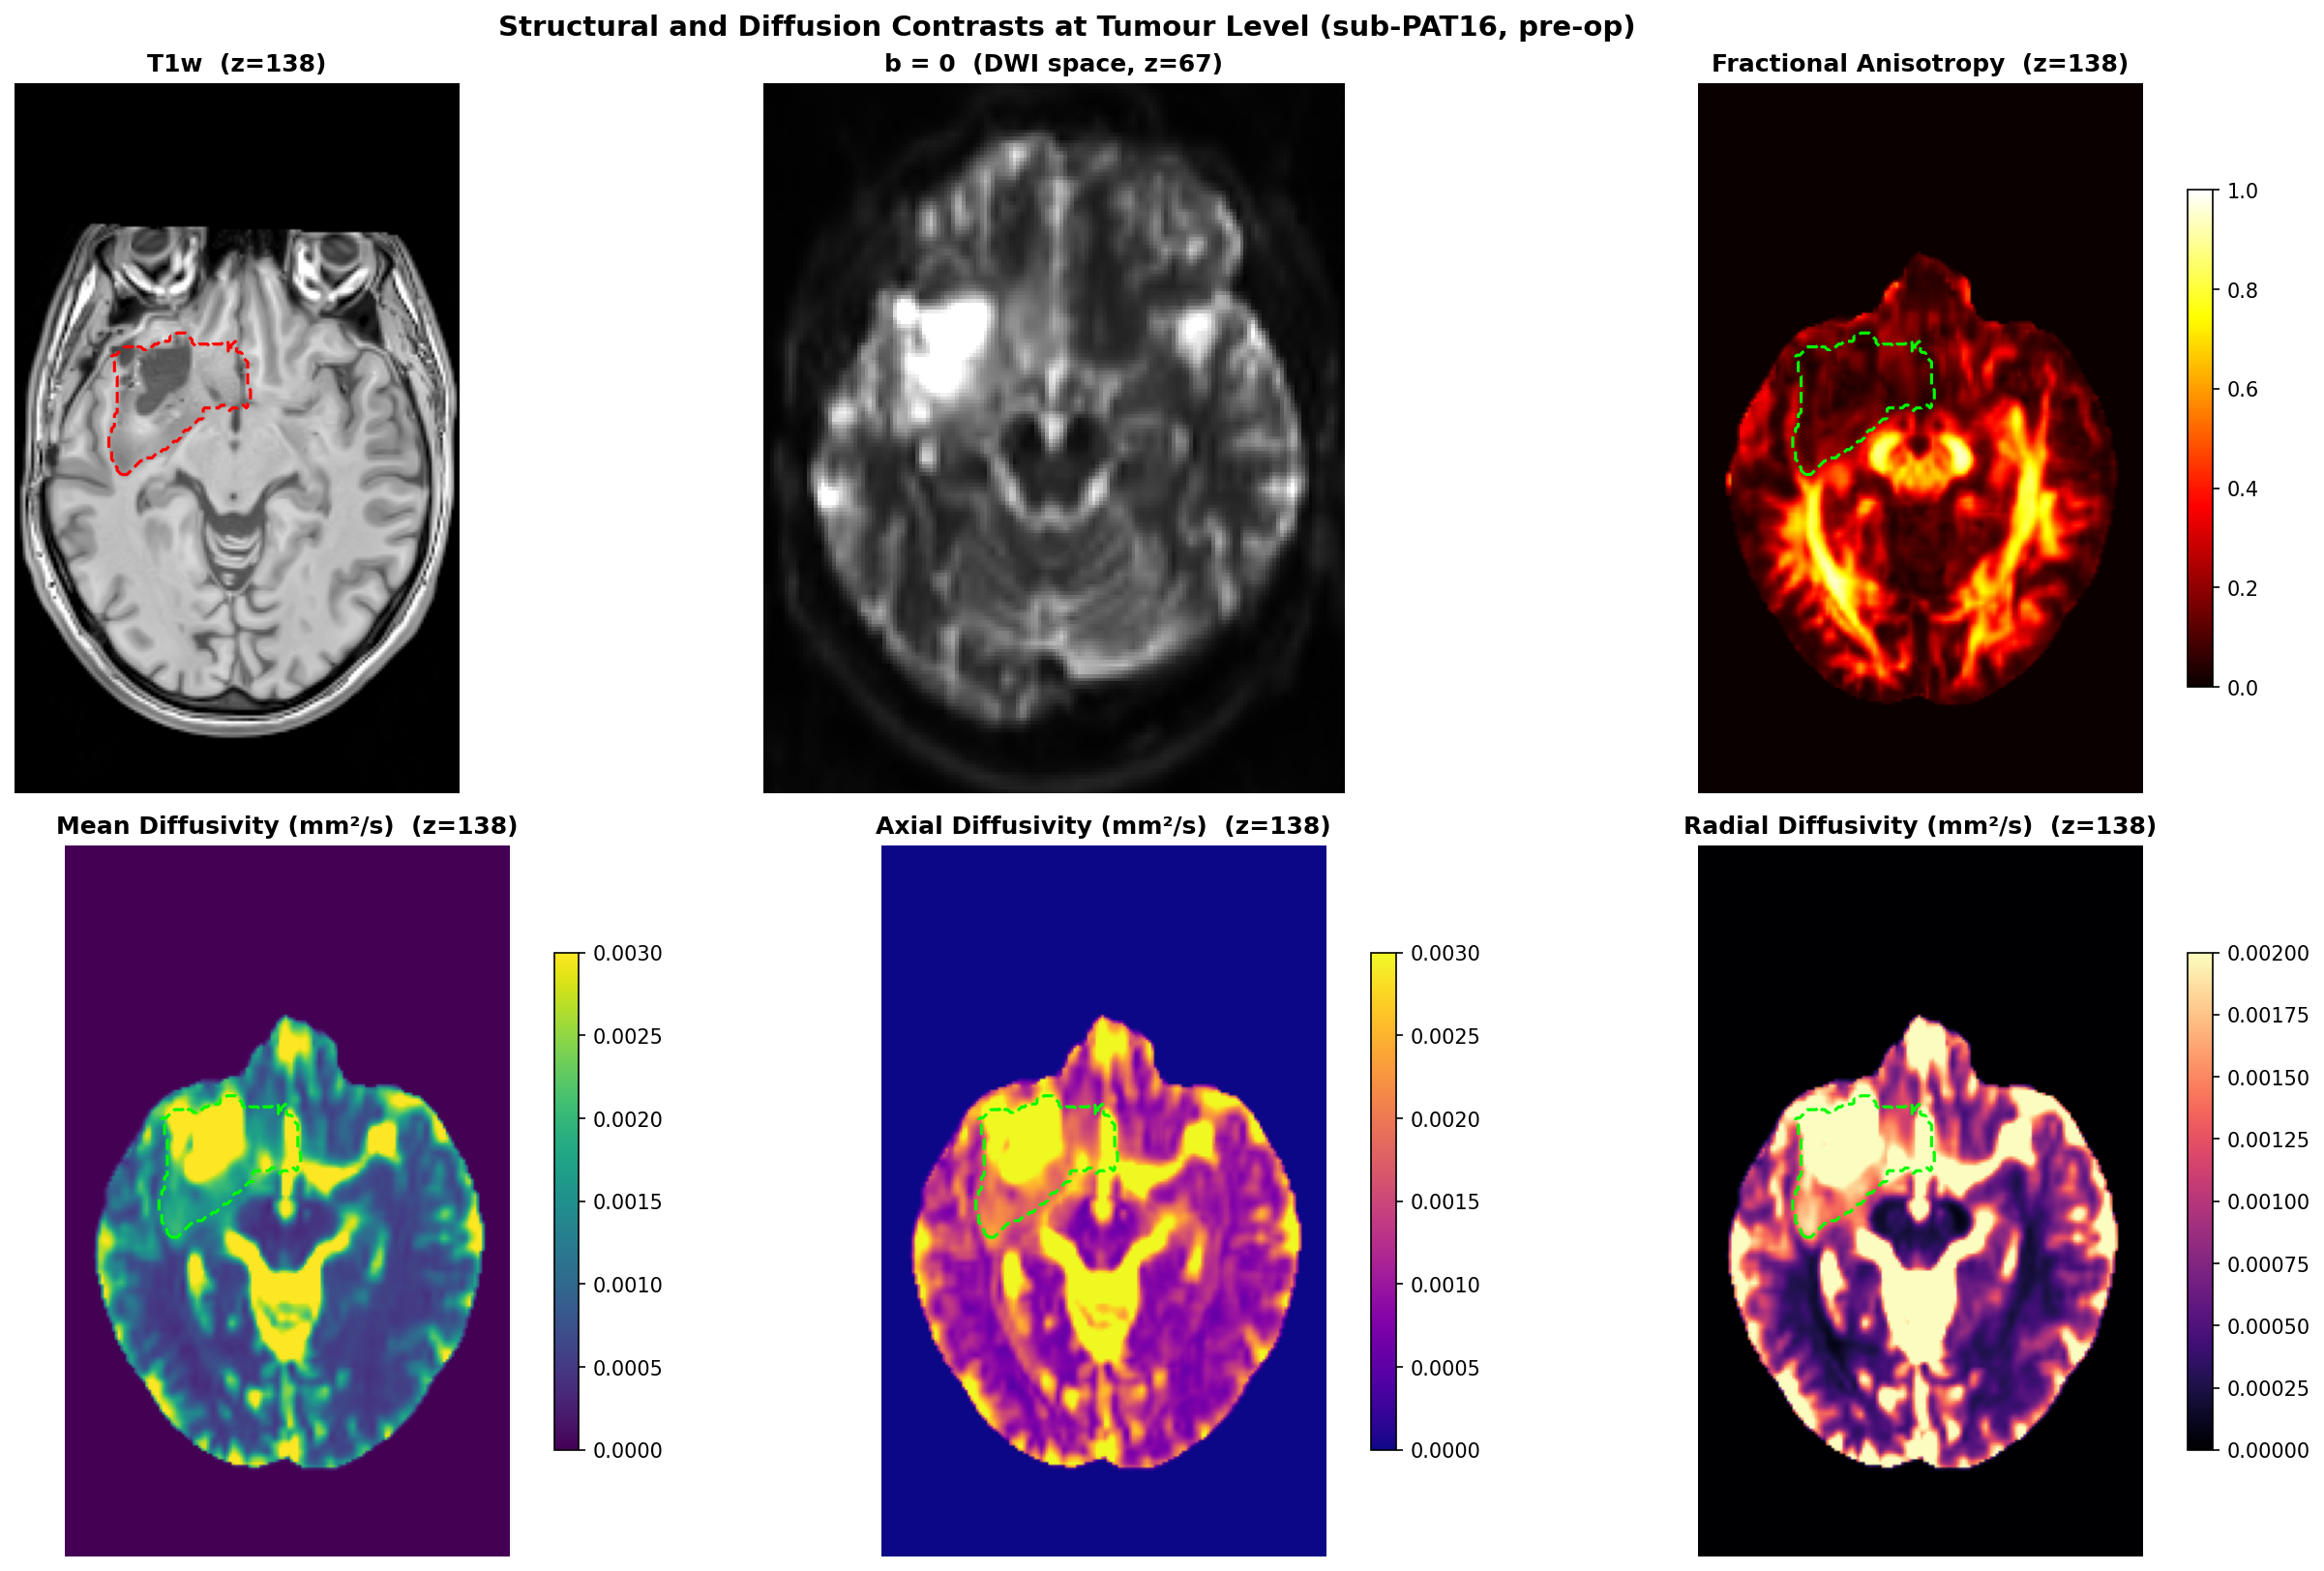

In [79]:
def _to_ras(img):
    """Reorient a NIfTI image to RAS+ canonical axes."""
    return nib.as_closest_canonical(img)

# Load DTI maps -- try pipeline (T1w space), then longitudinal
dti_maps = {}
for metric in ['fa', 'md', 'ad', 'rd']:
    for path_template in [
        REG_DIR / 'ses-preop' / f'{metric}_space-T1w.nii.gz',
        LONG_DIR / f'{metric}_preop_in_postop.nii.gz',
    ]:
        if path_template.exists():
            img = _to_ras(nib.load(str(path_template)))
            dti_maps[metric.upper()] = np.asarray(img.dataobj).astype(np.float32)
            print(f'{metric.upper()}: loaded from {path_template.name}, '
                  f'shape={dti_maps[metric.upper()].shape}')
            break
    else:
        print(f'{metric.upper()}: not found')

# Load T1w (fmriprep, native space -- same as DTI maps)
t1w_data = None
t1w_path = DERIV_PROJ / 'fmriprep' / 'sub-PAT16' / 'ses-preop' / 'anat' / \
           'sub-PAT16_ses-preop_desc-preproc_T1w.nii.gz'
if t1w_path.exists():
    t1w_img = _to_ras(nib.load(str(t1w_path)))
    t1w_data = np.asarray(t1w_img.dataobj).astype(np.float32)
    print(f'T1w: loaded from {t1w_path.name}, shape={t1w_data.shape}')
else:
    print('T1w: not found')

# Load b=0 reference (qsiprep, ACPC space) and reorient to RAS
b0_data = None
b0_affine = None
b0_path = DERIV_PROJ / 'qsiprep' / 'sub-PAT16' / 'ses-preop' / 'dwi' / \
          'sub-PAT16_ses-preop_space-ACPC_dwiref.nii.gz'
if b0_path.exists():
    b0_img = _to_ras(nib.load(str(b0_path)))
    b0_data = np.asarray(b0_img.dataobj).astype(np.float32)
    b0_affine = b0_img.affine
    print(f'b=0: loaded from {b0_path.name}, '
          f'reoriented to RAS, shape={b0_data.shape}')
else:
    print('b=0 (dwiref): not found')

# Load tumour mask to find the axial slice at tumour level
tumor_mask_path = BIDS_ROOT / 'derivatives' / 'tumor_masks' / 'sub-PAT16' / \
                  'anat' / 'sub-PAT16_space_T1_label-tumor_binary.nii.gz'
tmask_data = None
if tumor_mask_path.exists():
    tmask_img = _to_ras(nib.load(str(tumor_mask_path)))
    tmask_data = np.asarray(tmask_img.dataobj)
    tumor_z_extent = (tmask_data > 0).sum(axis=(0, 1))
    best_z = int(np.argmax(tumor_z_extent))
    print(f'Tumour mask loaded — best axial slice at z={best_z}')
else:
    best_z = None
    print('Tumour mask not found; will fall back to mid-slice')

if dti_maps:
    fig, axes = plt.subplots(2, 3, figsize=(18, 11))
    fig.suptitle('Structural and Diffusion Contrasts at Tumour Level '
                 '(sub-PAT16, pre-op)',
                 fontsize=14, fontweight='bold')

    # -- Row 1: T1w, b=0, FA ------------------------------------------------
    # T1w panel (T1w space, radiological: R on viewer's left)
    ax = axes[0, 0]
    if t1w_data is not None:
        sz = best_z if best_z is not None else t1w_data.shape[2] // 2
        vmax_t1 = np.percentile(t1w_data[t1w_data > 0], 99)
        ax.imshow(t1w_data[::-1, :, sz].T, origin='lower', cmap='gray',
                  vmin=0, vmax=vmax_t1, aspect='equal')
        if tmask_data is not None:
            ax.contour(tmask_data[::-1, :, sz].T, levels=[0.5],
                       colors='red', linewidths=1.5, linestyles='--')
        ax.set_title(f'T1w  (z={sz})', fontweight='bold')
    else:
        ax.text(0.5, 0.5, 'T1w\nnot available',
                ha='center', va='center', transform=ax.transAxes)
        ax.set_title('T1w')
    ax.axis('off')

    # b=0 panel (ACPC / DWI space, reoriented to RAS)
    ax = axes[0, 1]
    if b0_data is not None and tmask_data is not None:
        tumor_voxels = np.argwhere(tmask_data > 0)
        centroid_vox = tumor_voxels.mean(axis=0)
        centroid_world = nib.affines.apply_affine(tmask_img.affine,
                                                  centroid_vox)
        centroid_b0 = nib.affines.apply_affine(
            np.linalg.inv(b0_affine), centroid_world)
        b0_z = int(np.clip(round(centroid_b0[2]), 0, b0_data.shape[2] - 1))
    elif b0_data is not None:
        b0_z = b0_data.shape[2] // 2
    else:
        b0_z = 0

    if b0_data is not None:
        vmax_b0 = np.percentile(b0_data[b0_data > 0], 99)
        ax.imshow(b0_data[::-1, :, b0_z].T, origin='lower', cmap='gray',
                  vmin=0, vmax=vmax_b0, aspect='equal')
        ax.set_title(f'b = 0  (DWI space, z={b0_z})', fontweight='bold')
    else:
        ax.text(0.5, 0.5, 'b = 0\nnot available',
                ha='center', va='center', transform=ax.transAxes)
        ax.set_title('b = 0')
    ax.axis('off')

    # FA panel (T1w space, radiological)
    ax = axes[0, 2]
    if 'FA' in dti_maps:
        vol = dti_maps['FA']
        sz = best_z if best_z is not None else vol.shape[2] // 2
        im = ax.imshow(np.clip(vol[::-1, :, sz].T, 0, 1),
                       origin='lower', cmap='hot', vmin=0, vmax=1,
                       aspect='equal')
        if tmask_data is not None:
            ax.contour(tmask_data[::-1, :, sz].T, levels=[0.5],
                       colors='lime', linewidths=1.5, linestyles='--')
        ax.set_title(f'Fractional Anisotropy  (z={sz})', fontweight='bold')
        plt.colorbar(im, ax=ax, shrink=0.7)
    else:
        ax.text(0.5, 0.5, 'FA\nnot available',
                ha='center', va='center', transform=ax.transAxes)
        ax.set_title('FA')
    ax.axis('off')

    # -- Row 2: MD, AD, RD ---------------------------------------------------
    row2_metrics = [
        ('MD', 'viridis', 0, 3e-3, 'Mean Diffusivity (mm\u00b2/s)'),
        ('AD', 'plasma',  0, 3e-3, 'Axial Diffusivity (mm\u00b2/s)'),
        ('RD', 'magma',   0, 2e-3, 'Radial Diffusivity (mm\u00b2/s)'),
    ]
    for col, (metric_name, cmap, vmin, vmax, title) in enumerate(row2_metrics):
        ax = axes[1, col]
        if metric_name in dti_maps:
            vol = dti_maps[metric_name]
            sz = best_z if best_z is not None else vol.shape[2] // 2
            im = ax.imshow(np.clip(vol[::-1, :, sz].T, vmin, vmax),
                           origin='lower', cmap=cmap, vmin=vmin, vmax=vmax,
                           aspect='equal')
            if tmask_data is not None:
                ax.contour(tmask_data[::-1, :, sz].T, levels=[0.5],
                           colors='lime', linewidths=1.5, linestyles='--')
            ax.set_title(f'{title}  (z={sz})', fontweight='bold')
            plt.colorbar(im, ax=ax, shrink=0.7)
        else:
            ax.text(0.5, 0.5, f'{metric_name}\nnot available',
                    ha='center', va='center', transform=ax.transAxes)
            ax.set_title(metric_name)
        ax.axis('off')

    plt.tight_layout()
    fig.savefig(FIG_DIR / 'figC04_01_dti_maps.png', bbox_inches='tight')
    plt.show()

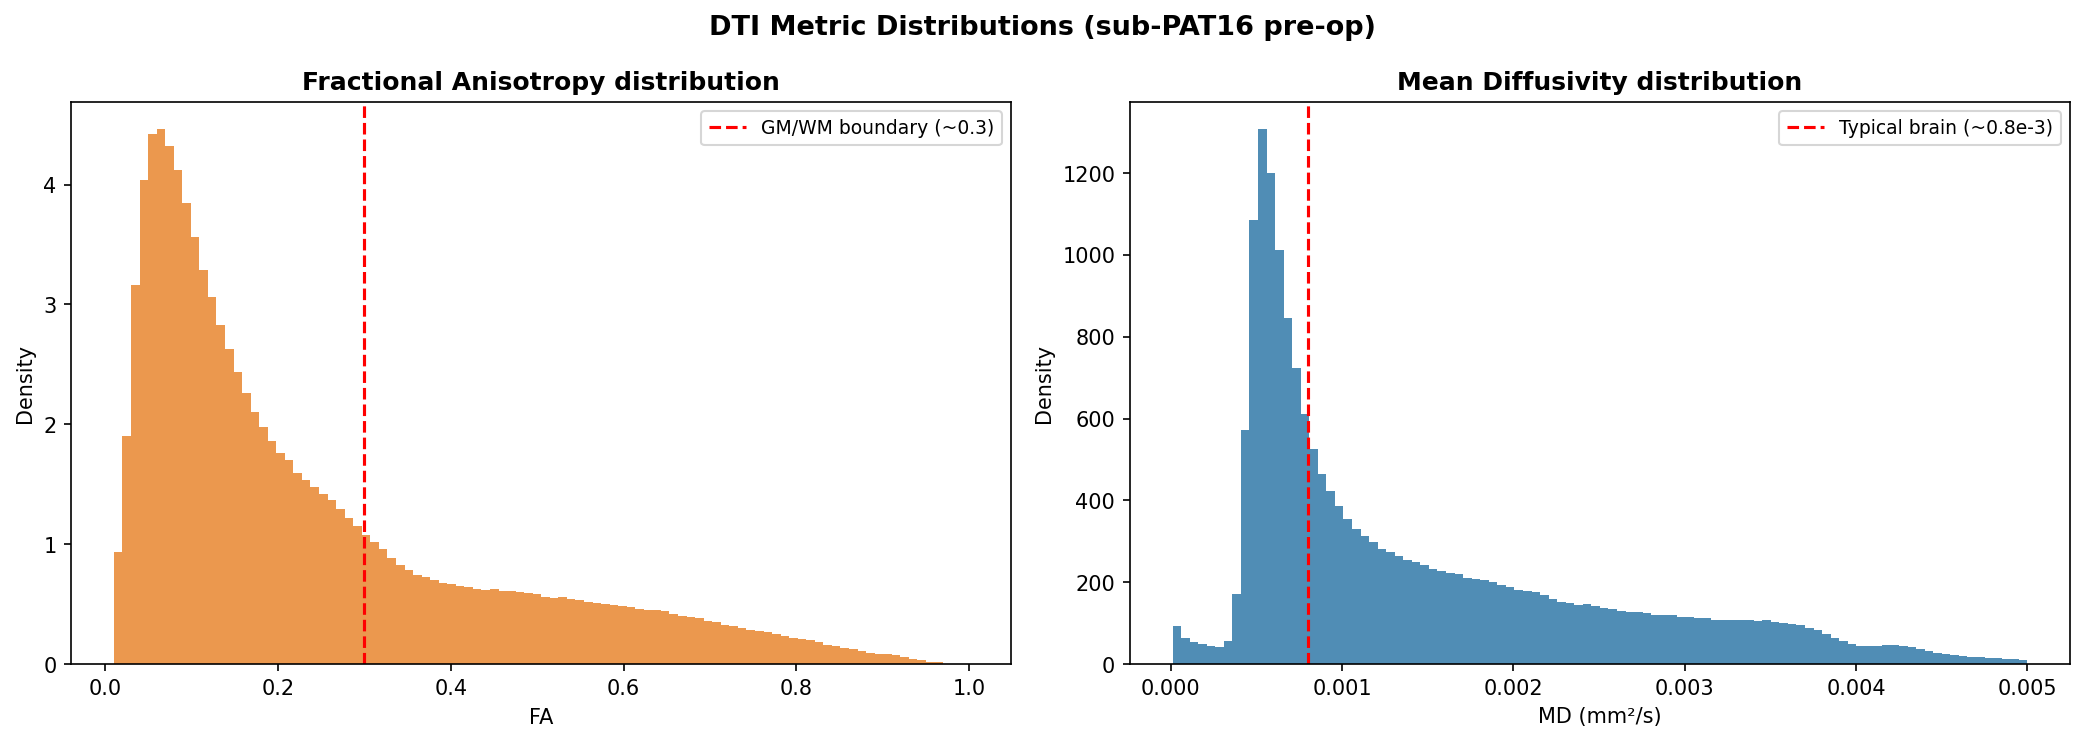

In [80]:
# FA and MD histograms
if 'FA' in dti_maps and 'MD' in dti_maps:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle('DTI Metric Distributions (sub-PAT16 pre-op)',
                 fontsize=13, fontweight='bold')

    fa_brain = dti_maps['FA'][(dti_maps['FA'] > 0.01) & (dti_maps['FA'] < 1.0)]
    axes[0].hist(fa_brain, bins=100, color='#E67E22', alpha=0.8, density=True)
    axes[0].axvline(0.3, color='red', ls='--', label='GM/WM boundary (~0.3)')
    axes[0].set_xlabel('FA')
    axes[0].set_ylabel('Density')
    axes[0].set_title('Fractional Anisotropy distribution', fontweight='bold')
    axes[0].legend(fontsize=9)

    md_brain = dti_maps['MD'][(dti_maps['MD'] > 1e-5) & (dti_maps['MD'] < 5e-3)]
    axes[1].hist(md_brain, bins=100, color='#2471A3', alpha=0.8, density=True)
    axes[1].axvline(0.8e-3, color='red', ls='--', label='Typical brain (~0.8e-3)')
    axes[1].set_xlabel('MD (mm\u00b2/s)')
    axes[1].set_ylabel('Density')
    axes[1].set_title('Mean Diffusivity distribution', fontweight='bold')
    axes[1].legend(fontsize=9)

    plt.tight_layout()
    fig.savefig(FIG_DIR / 'figC04_02_dti_histograms.png', bbox_inches='tight')
    plt.show()

---
## 4. Structural Connectivity

### The connectome as a weighted graph

Structural connectivity (SC) represents the brain as a **weighted undirected
graph** $G = (V, E, W)$, where the set of nodes $V = \{1, \dots, n\}$ are
brain regions, the edges $E$ are white matter fibre bundles linking them,
and the weight $w_{ij} \in W$ quantifies connection strength between
regions $i$ and $j$.

The SC matrix $\mathbf{C} \in \mathbb{R}^{n \times n}$ stores these weights:

$$C_{ij} = \sum_{s \in \mathcal{S}_{ij}} \mu_s$$

where $\mathcal{S}_{ij}$ is the set of tractography streamlines whose
endpoints fall in regions $i$ and $j$, and $\mu_s$ is the weight assigned
to streamline $s$.  In the simplest case, $\mu_s = 1$ (raw streamline count),
but this makes the matrix sensitive to seeding density and tractography
parameters rather than to actual anatomy
([Jones et al., 2013](https://doi.org/10.1016/j.neuroimage.2012.01.024)).

### Parcellation: Desikan–Killiany atlas from FreeSurfer

The nodes $V$ are defined by a **cortical parcellation** — a partition of
the cortical ribbon into anatomically labelled regions of interest (ROIs).
For PAT16 we use the **Desikan–Killiany (DK) atlas** with $n = 68$
cortical parcels (34 per hemisphere), the standard output of FreeSurfer's
`aparc+aseg` segmentation.

**How the parcellation is derived for our data:**

| Session | FreeSurfer variant | Rationale |
|---------|-------------------|-----------|
| Pre-op  | Standard `recon-all` | Cortical surface reconstruction is reliable when the glioma's mass effect is moderate |
| Post-op | `recon-all-clinical` (SynthSeg-based) | The resection cavity breaks standard surface reconstruction; the SynthSeg-based approach handles pathological anatomy robustly |

In both cases the key output is `mri/aparc+aseg.mgz`, which assigns every
voxel to one of the DK atlas labels.  This volume is then converted from
FreeSurfer's conformed space to T1w native space
(`aparc+aseg_space-T1w.nii.gz`) during the co-registration step
(`register_to_t1w.sh`).

For the connectome, MRtrix3's `labelconvert` remaps the FreeSurfer label
integers to a contiguous $1 \dots 68$ index (using the
`fs_default.txt` lookup table), producing a **parcellation nodes image** in
diffusion space that `tck2connectome` reads to assign streamline endpoints
to regions.

### From tractography to the SC matrix

The SC matrix is built from the whole-brain tractogram in four steps:

1. **Fibre orientation estimation (CSD).**  Multi-shell multi-tissue
   constrained spherical deconvolution (`dwi2fod msmt_csd` in MRtrix3)
   estimates the fibre orientation distribution (FOD) in every voxel from
   the preprocessed DWI data.  Unlike the single-tensor DTI model
   (Section 2), CSD can resolve **crossing fibres** — critical in regions
   such as the centrum semiovale where corticospinal, callosal, and
   association fibres intersect.

2. **Anatomically-constrained tractography (ACT).**  A five-tissue-type
   (5TT) image — segmenting cortical GM, subcortical GM, WM, CSF, and
   pathological tissue — is derived from the T1w using `5ttgen fsl`.
   Probabilistic streamline tractography (`tckgen` with the iFOD2
   algorithm) seeds $10\,\text{M}$ streamlines throughout the WM and uses
   the 5TT image to enforce anatomically plausible termination: streamlines
   must originate and terminate in grey matter, and are rejected if they
   enter CSF
   ([Smith et al., 2012](https://doi.org/10.1016/j.neuroimage.2012.06.005)).

3. **SIFT2 streamline weighting.**  Raw streamline count is a poor proxy for
   connection density because tractography is biased by fibre geometry
   (longer tracts, sharp bends, and crossing regions are under-represented).
   **SIFT2** (Spherical-deconvolution Informed Filtering of Tractograms,
   version 2;
   [Smith et al., 2015](https://doi.org/10.1016/j.neuroimage.2015.06.092))
   assigns a cross-sectional area coefficient $\mu_s$ to each streamline
   $s$ by solving a global optimisation problem:

$$\min_{\boldsymbol{\mu}} \sum_{\text{voxels}\, v}
  \left\| \text{FOD}(v) - \sum_{s \ni v} \mu_s \, \delta_s(v) \right\|^2
  \quad \text{subject to} \quad \mu_s \geq 0$$

   where $\delta_s(v)$ is the unit-length tangent of streamline $s$ through
   voxel $v$.  The weights $\mu_s$ are adjusted so that the reconstructed
   fibre density (summed streamline contributions) matches the FOD estimated
   from the diffusion data.  This makes the resulting SC matrix
   **quantitative** and proportional to fibre cross-sectional area, rather
   than merely reflecting arbitrary seeding parameters.

4. **Connectome construction.**  MRtrix3's `tck2connectome` reads the
   weighted tractogram and the parcellation nodes image, and accumulates
   $C_{ij} = \sum_{s \in \mathcal{S}_{ij}} \mu_s$ for every region pair.
   The result is a symmetric $68 \times 68$ matrix stored as
   `sc_sift2.npy`.

### Application to PAT16

For **sub-PAT16 pre-op**, the SC matrix (`SCthrAn.mat` in the TVB
derivatives, or `sc_sift2.npy` in `derivatives/connectivity/`) was computed
following the full pipeline above: QSIPrep → MRtrix3 CSD → ACT (10 M
streamlines) → SIFT2 → `tck2connectome` against the DK68 parcellation
derived from the pre-op FreeSurfer `recon-all` segmentation.  The loaded
matrix has shape $(68, 68)$ with a density of $\approx 0.48$ (roughly half
of all possible cortical region pairs are connected by at least one
SIFT2-weighted streamline).

#### How $w_{ij}$ is defined in our SC matrix

Each entry $w_{ij} = C_{ij}$ in the PAT16 SC matrix is the **SIFT2-weighted
fibre connection density** between parcels $i$ and $j$:

$$w_{ij} = \sum_{s \in \mathcal{S}_{ij}} \mu_s$$

where $\mu_s$ is the cross-sectional area coefficient assigned to
streamline $s$ by the SIFT2 optimisation.  This weight has a clear
biophysical interpretation: it is proportional to the **total intra-axonal
cross-sectional area** of the fibre bundle connecting the two regions
([Smith et al., 2015](https://doi.org/10.1016/j.neuroimage.2015.06.092)).

**Why not raw streamline count?**  Naive counting ($\mu_s = 1$) introduces
systematic biases:
- **Length bias:** Longer tracts have more opportunities to be terminated or
  mis-tracked, so distant connections are under-represented
  ([Girard et al., 2014](https://doi.org/10.1016/j.neuroimage.2014.02.009)).
- **Gyral bias:** Tractography seeds preferentially reach gyral crowns
  rather than sulcal fundi, distorting the apparent connectivity of
  adjacent parcels
  ([St-Onge et al., 2018](https://doi.org/10.1016/j.neuroimage.2017.12.049)).
- **Seeding density dependence:** Doubling the number of seeded streamlines
  doubles all counts without changing the underlying anatomy
  ([Jones et al., 2013](https://doi.org/10.1016/j.neuroimage.2012.01.024)).

SIFT2 mitigates these biases by fitting the streamline weights to the
independently measured FOD amplitudes, making $w_{ij}$ a property of the
tissue rather than of the tractography algorithm.

**Post-processing of the raw matrix:**

1. **Symmetrisation.**  Because streamline endpoints are assigned to the
   nearest parcel, small numerical asymmetries arise.  These are removed
   by averaging: $C_{ij} \leftarrow (C_{ij} + C_{ji}) / 2$.

2. **Thresholding.**  Entries below a noise floor (e.g., the lowest 1–5 %
   of non-zero weights) are set to zero.  This removes spurious
   connections from false-positive streamlines — a well-known limitation
   of diffusion tractography
   ([Maier-Hein et al., 2017](https://doi.org/10.1038/s41467-017-01285-x)).
   The thresholded and symmetrised matrix is what we load as `SCthrAn.mat`
   (SC-thresholded-Anatomical).

3. **Normalisation (optional).**  For visualisation and cross-subject
   comparison the matrix may be divided by its maximum entry, yielding
   $C_{ij}^{\text{norm}} \in [0, 1]$.  We apply this normalisation when
   plotting but retain the raw SIFT2 weights for quantitative analyses.

**Interpretation and caveats.**  Even with SIFT2, the SC matrix is an
*estimate* of structural connectivity and remains subject to:
- Tractography's inability to distinguish afferent from efferent connections
  (the matrix is treated as undirected)
  ([Jeurissen et al., 2019](https://doi.org/10.1016/j.neuroimage.2017.11.007));
- Partial-volume effects where tumour infiltration, oedema, or the
  resection cavity alter the FOD, potentially biasing the SIFT2 weights in
  perilesional tissue;
- The choice of parcellation granularity (DK68 is relatively coarse; finer
  atlases yield denser but noisier matrices).

For the **post-op** session (when available), the same pipeline is applied
using `recon-all-clinical` parcellation and post-op DWI, enabling
quantification of how tumour resection and brain shift have disrupted
specific white matter connections.

In [81]:
import pandas as pd

DK_FULL_NAMES = {
    'bankssts':                 'Banks of Superior Temporal Sulcus',
    'caudalanteriorcingulate':  'Caudal Anterior Cingulate',
    'caudalmiddlefrontal':      'Caudal Middle Frontal',
    'cuneus':                   'Cuneus',
    'entorhinal':               'Entorhinal',
    'fusiform':                 'Fusiform',
    'inferiorparietal':         'Inferior Parietal',
    'inferiortemporal':         'Inferior Temporal',
    'isthmuscingulate':         'Isthmus Cingulate',
    'lateraloccipital':         'Lateral Occipital',
    'lateralorbitofrontal':     'Lateral Orbitofrontal',
    'lingual':                  'Lingual',
    'medialorbitofrontal':      'Medial Orbitofrontal',
    'middletemporal':           'Middle Temporal',
    'parahippocampal':          'Parahippocampal',
    'paracentral':              'Paracentral',
    'parsopercularis':          'Pars Opercularis',
    'parsorbitalis':            'Pars Orbitalis',
    'parstriangularis':         'Pars Triangularis',
    'pericalcarine':            'Pericalcarine',
    'postcentral':              'Postcentral',
    'posteriorcingulate':       'Posterior Cingulate',
    'precentral':               'Precentral',
    'precuneus':                'Precuneus',
    'rostralanteriorcingulate': 'Rostral Anterior Cingulate',
    'rostralmiddlefrontal':     'Rostral Middle Frontal',
    'superiorfrontal':          'Superior Frontal',
    'superiorparietal':         'Superior Parietal',
    'superiortemporal':         'Superior Temporal',
    'supramarginal':            'Supramarginal',
    'frontalpole':              'Frontal Pole',
    'temporalpole':             'Temporal Pole',
    'transversetemporal':       'Transverse Temporal (Heschl)',
    'insula':                   'Insula',
}

LOBE_MAP = {
    'bankssts': 'Temporal', 'caudalanteriorcingulate': 'Cingulate',
    'caudalmiddlefrontal': 'Frontal', 'cuneus': 'Occipital',
    'entorhinal': 'Temporal', 'fusiform': 'Temporal',
    'inferiorparietal': 'Parietal', 'inferiortemporal': 'Temporal',
    'isthmuscingulate': 'Cingulate', 'lateraloccipital': 'Occipital',
    'lateralorbitofrontal': 'Frontal', 'lingual': 'Occipital',
    'medialorbitofrontal': 'Frontal', 'middletemporal': 'Temporal',
    'parahippocampal': 'Temporal', 'paracentral': 'Frontal',
    'parsopercularis': 'Frontal', 'parsorbitalis': 'Frontal',
    'parstriangularis': 'Frontal', 'pericalcarine': 'Occipital',
    'postcentral': 'Parietal', 'posteriorcingulate': 'Cingulate',
    'precentral': 'Frontal', 'precuneus': 'Parietal',
    'rostralanteriorcingulate': 'Cingulate', 'rostralmiddlefrontal': 'Frontal',
    'superiorfrontal': 'Frontal', 'superiorparietal': 'Parietal',
    'superiortemporal': 'Temporal', 'supramarginal': 'Parietal',
    'frontalpole': 'Frontal', 'temporalpole': 'Temporal',
    'transversetemporal': 'Temporal', 'insula': 'Insular',
}

rows = []
for idx, name in enumerate(DK68_NAMES, start=1):
    hemi, short = name.split('-', 1)
    rows.append({
        'Index': idx,
        'Hemisphere': 'Left' if hemi == 'lh' else 'Right',
        'FreeSurfer label': name,
        'Region': DK_FULL_NAMES[short],
        'Lobe': LOBE_MAP[short],
    })

df_dk68 = pd.DataFrame(rows).set_index('Index')

print(f'Desikan–Killiany parcellation: {len(df_dk68)} cortical regions '
      f'(from FreeSurfer aparc+aseg)')
print(f'Hemispheres: {df_dk68["Hemisphere"].value_counts().to_dict()}')
print(f'Lobes: {df_dk68["Lobe"].value_counts().to_dict()}')
print()

with pd.option_context('display.max_rows', None, 'display.max_colwidth', 40):
    display(df_dk68)

Desikan–Killiany parcellation: 68 cortical regions (from FreeSurfer aparc+aseg)
Hemispheres: {'Left': 34, 'Right': 34}
Lobes: {'Frontal': 22, 'Temporal': 18, 'Parietal': 10, 'Cingulate': 8, 'Occipital': 8, 'Insular': 2}



,Hemisphere,FreeSurfer label,Region,Lobe
Index,,,,
1,Left,lh-bankssts,Banks of Superior Temporal Sulcus,Temporal
2,Left,lh-caudalanteriorcingulate,Caudal Anterior Cingulate,Cingulate
3,Left,lh-caudalmiddlefrontal,Caudal Middle Frontal,Frontal
4,Left,lh-cuneus,Cuneus,Occipital
5,Left,lh-entorhinal,Entorhinal,Temporal
6,Left,lh-fusiform,Fusiform,Temporal
7,Left,lh-inferiorparietal,Inferior Parietal,Parietal
8,Left,lh-inferiortemporal,Inferior Temporal,Temporal
9,Left,lh-isthmuscingulate,Isthmus Cingulate,Cingulate


In [82]:
# Load SC matrices
sc_mat_path = TVB_DIR / 'ses-preop' / 'SCthrAn.mat'
if sc_mat_path.exists():
    sc_data = loadmat(str(sc_mat_path))
    SC_pre = None
    for _k in ('SC_thr', 'SCthrAn', 'SC', 'weights'):
        if _k in sc_data:
            SC_pre = sc_data[_k].astype(float)
            break
    if SC_pre is None:
        for _k, _v in sc_data.items():
            if isinstance(_v, np.ndarray) and _v.ndim == 2 and _v.shape[0] == _v.shape[1]:
                SC_pre = _v.astype(float)
                break
    print(f'Loaded pre-op SC from TVB: shape {SC_pre.shape}')
else:
    sc_npy = CONN_DIR / 'ses-preop' / 'sc_sift2.npy'
    SC_pre_full = np.load(str(sc_npy))
    SC_pre = SC_pre_full[:N_REGIONS, :N_REGIONS]
    print(f'Loaded pre-op SC from pipeline: shape {SC_pre.shape}')

SC_pre_norm = SC_pre / SC_pre.max() if SC_pre.max() > 0 else SC_pre
N_REGIONS = SC_pre.shape[0]

sc_post_npy = CONN_DIR / 'ses-postop' / 'sc_sift2.npy'
HAS_POST_SC = False
if sc_post_npy.exists():
    SC_post_full = np.load(str(sc_post_npy))
    SC_post = SC_post_full[:N_REGIONS, :N_REGIONS]
    SC_post_norm = SC_post / SC_post.max() if SC_post.max() > 0 else SC_post
    HAS_POST_SC = True
    print(f'Loaded post-op SC: shape {SC_post.shape}')

sc_degree_pre = SC_pre_norm.sum(axis=1)
print(f'SC density: {np.count_nonzero(SC_pre) / SC_pre.size:.3f}')

Loaded pre-op SC from TVB: shape (68, 68)
Loaded post-op SC: shape (68, 68)
SC density: 0.475


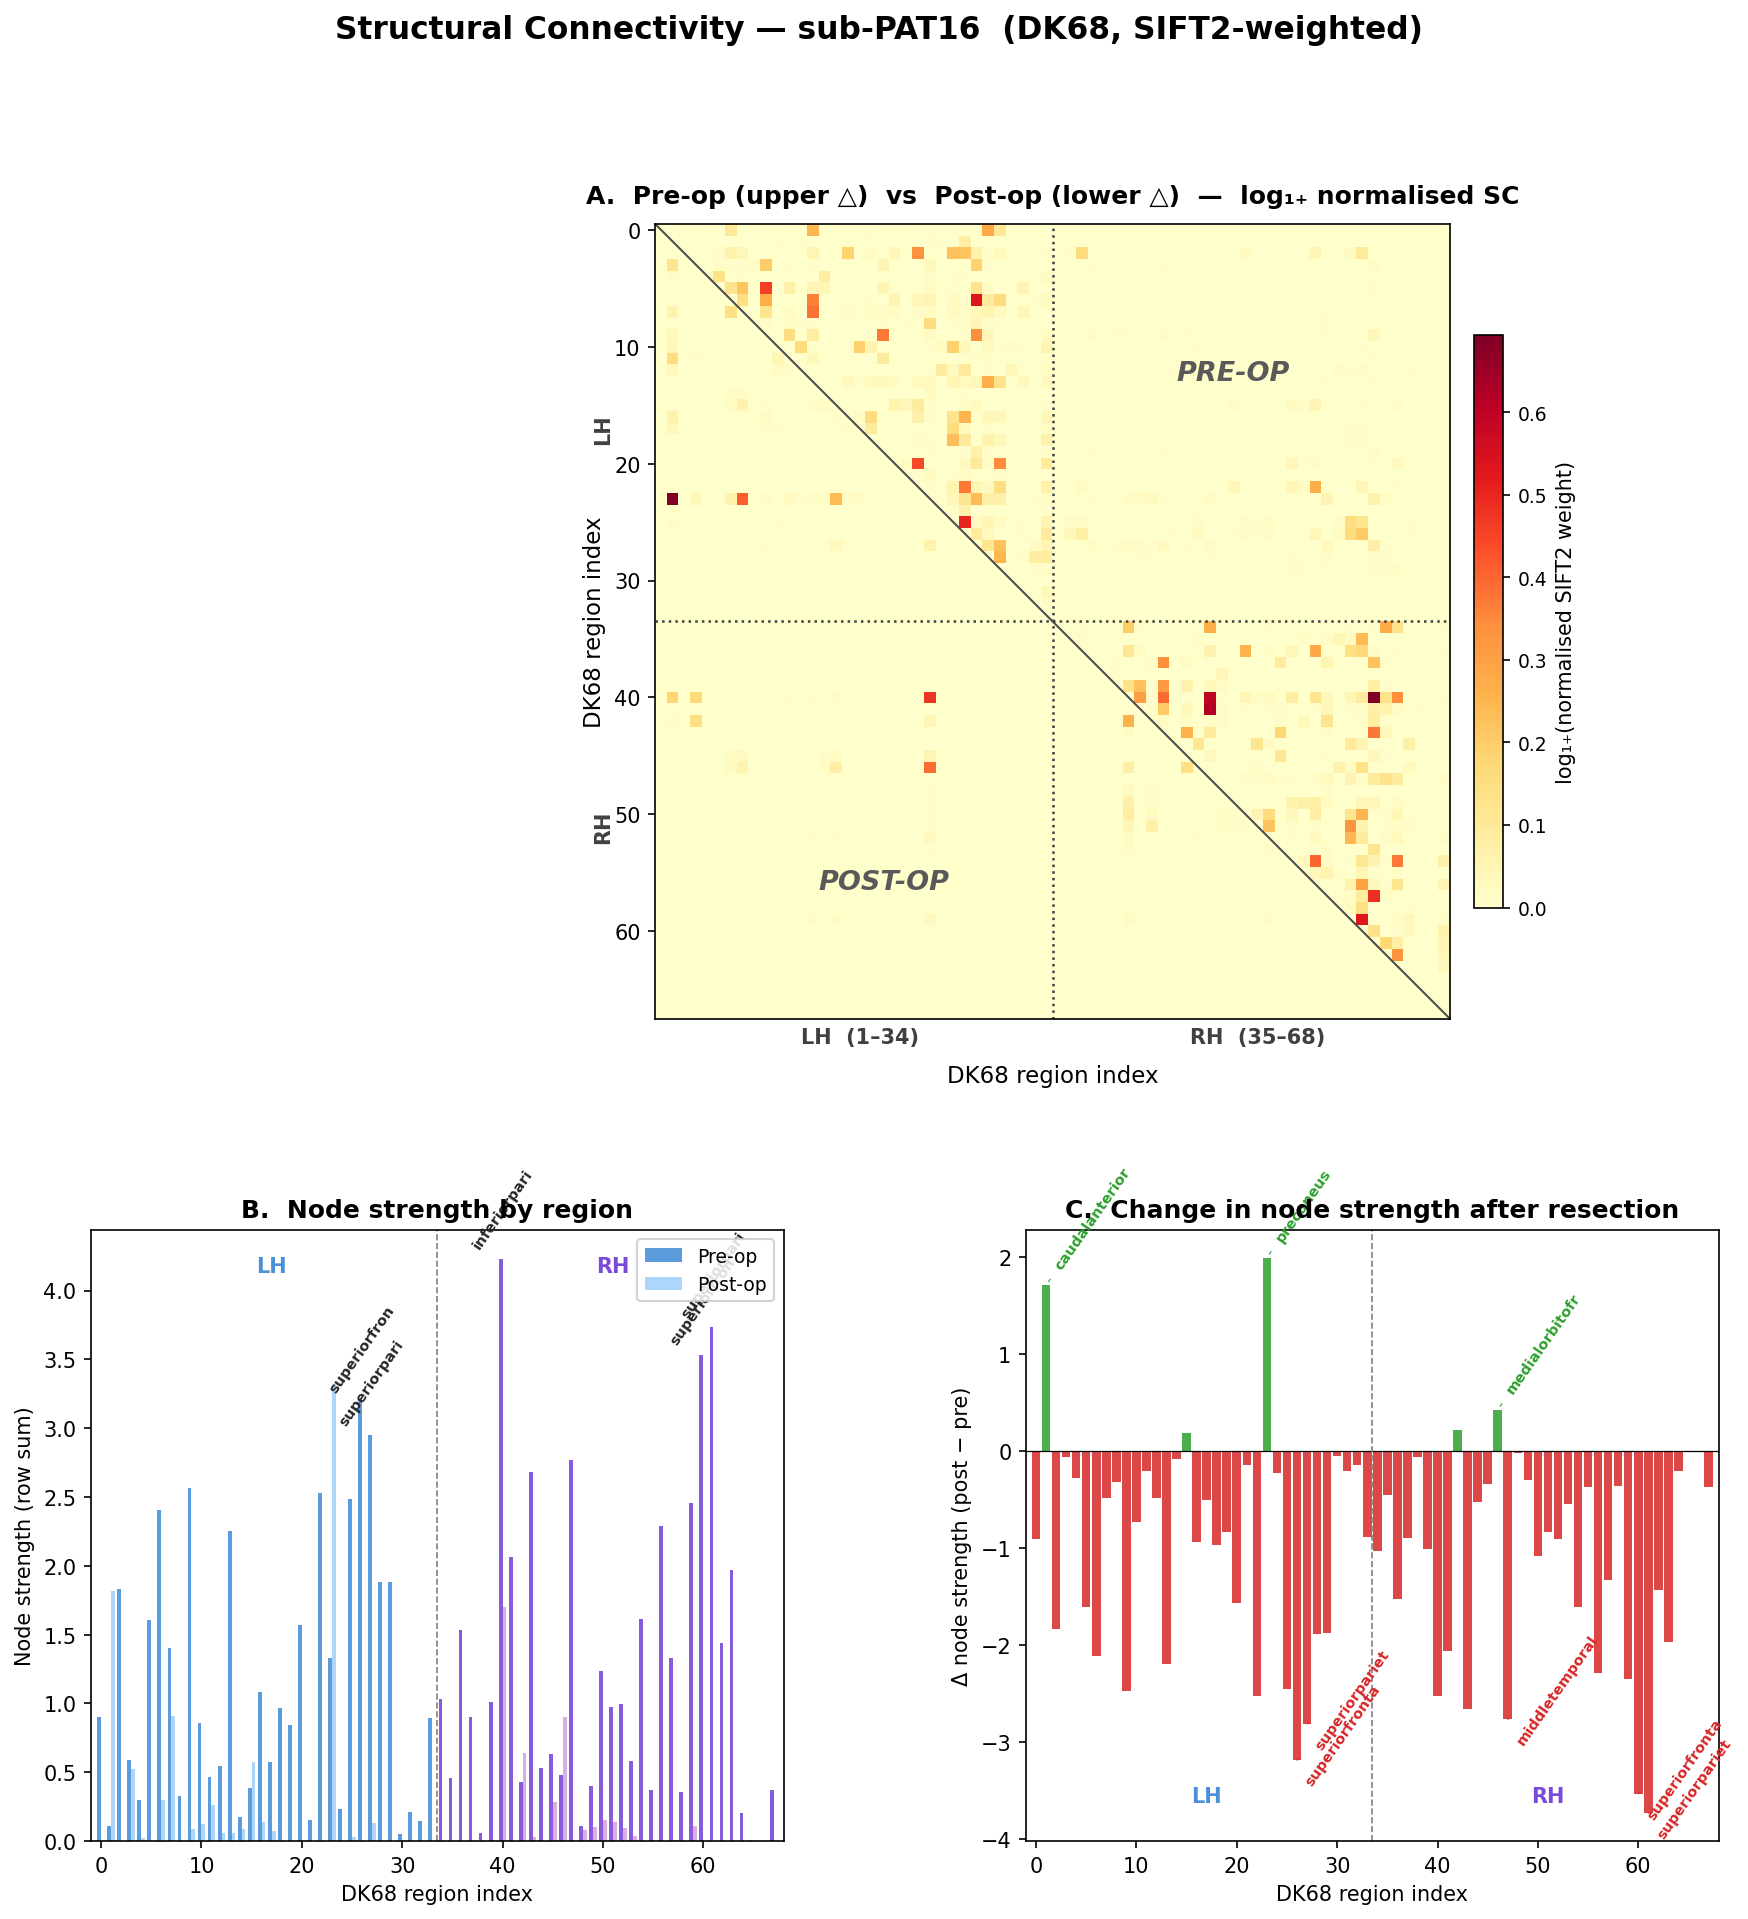

In [87]:
from matplotlib.gridspec import GridSpec
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

n_lh = N_REGIONS // 2
SC_pre_log  = np.log1p(SC_pre_norm)
SC_post_log = np.log1p(SC_post_norm) if HAS_POST_SC else None

# ── combined matrix: upper-tri = pre-op, lower-tri = post-op ──
SC_combined = np.full_like(SC_pre_log, np.nan)
for i in range(N_REGIONS):
    for j in range(i, N_REGIONS):
        SC_combined[i, j] = SC_pre_log[i, j]
    if HAS_POST_SC:
        for j in range(0, i):
            SC_combined[i, j] = SC_post_log[i, j]

vmin, vmax = 0.0, np.nanmax(SC_combined)

# ── layout: top row = big combined matrix; bottom row = two bar charts ──
fig = plt.figure(figsize=(14, 14))
gs  = GridSpec(2, 2, figure=fig, height_ratios=[1.3, 1],
               hspace=0.30, wspace=0.35)

ax_mat = fig.add_subplot(gs[0, :])
ax_str = fig.add_subplot(gs[1, 0])
ax_dlt = fig.add_subplot(gs[1, 1])

fig.suptitle('Structural Connectivity — sub-PAT16  (DK68, SIFT2-weighted)',
             fontsize=15, fontweight='bold', y=0.98)

# ────────────────── Panel A: combined SC matrix ──────────────────
cmap = plt.cm.YlOrRd.copy()
cmap.set_bad(color='white')

im = ax_mat.imshow(SC_combined, cmap=cmap, aspect='equal',
                   interpolation='nearest', vmin=vmin, vmax=vmax)

ax_mat.plot([-0.5, N_REGIONS - 0.5], [-0.5, N_REGIONS - 0.5],
            color='0.30', lw=1.0, ls='-')
ax_mat.axhline(n_lh - 0.5, color='0.25', lw=1.2, ls=':')
ax_mat.axvline(n_lh - 0.5, color='0.25', lw=1.2, ls=':')

ax_mat.set_xlim(-0.5, N_REGIONS - 0.5)
ax_mat.set_ylim(N_REGIONS - 0.5, -0.5)

ax_mat.set_xlabel('DK68 region index', fontsize=11, labelpad=8)
ax_mat.set_ylabel('DK68 region index', fontsize=11)
ax_mat.set_title('A.  Pre-op (upper △)  vs  Post-op (lower △)'
                 '  —  log₁₊ normalised SC',
                 fontweight='bold', fontsize=12, pad=10)

ax_mat.set_xticks([n_lh // 2, n_lh + n_lh // 2])
ax_mat.set_xticklabels(['LH  (1–34)', 'RH  (35–68)'],
                        fontsize=10, fontweight='bold', color='0.25')
ax_mat.tick_params(axis='x', length=0, pad=4)
ax_mat.tick_params(axis='x', top=False, labeltop=False)

ax_mat.text(-5, n_lh / 2, 'LH', ha='center', va='center', fontsize=10,
            fontweight='bold', color='0.25', rotation=90)
ax_mat.text(-5, n_lh + n_lh / 2, 'RH', ha='center', va='center', fontsize=10,
            fontweight='bold', color='0.25', rotation=90)

ax_mat.annotate('PRE-OP', xy=(N_REGIONS * 0.72, N_REGIONS * 0.18),
                fontsize=13, fontweight='bold', color='0.35', fontstyle='italic',
                ha='center', va='center')
if HAS_POST_SC:
    ax_mat.annotate('POST-OP', xy=(N_REGIONS * 0.28, N_REGIONS * 0.82),
                    fontsize=13, fontweight='bold', color='0.35', fontstyle='italic',
                    ha='center', va='center')

cb = plt.colorbar(im, ax=ax_mat, shrink=0.72, pad=0.015)
cb.set_label('log₁₊(normalised SIFT2 weight)', fontsize=10)
cb.ax.tick_params(labelsize=9)

# ────────────────── Panel B: node strength ──────────────────
sc_degree_post = SC_post_norm.sum(axis=1) if HAS_POST_SC else None

bar_x   = np.arange(N_REGIONS)
bar_w   = 0.38
c_pre   = ['#4a90d9'] * n_lh + ['#7a4ad9'] * n_lh
c_post  = ['#90caf9'] * n_lh + ['#ce93d8'] * n_lh

ax_str.bar(bar_x - bar_w / 2, sc_degree_pre, width=bar_w, color=c_pre,
           alpha=0.9, label='Pre-op')
if HAS_POST_SC:
    ax_str.bar(bar_x + bar_w / 2, sc_degree_post, width=bar_w, color=c_post,
               alpha=0.75, label='Post-op')

ax_str.axvline(n_lh - 0.5, color='grey', lw=0.8, ls='--')
ax_str.set_xlabel('DK68 region index', fontsize=10)
ax_str.set_ylabel('Node strength (row sum)', fontsize=10)
ax_str.set_title('B.  Node strength by region', fontweight='bold', fontsize=12)
ax_str.set_xlim(-1, N_REGIONS)
ax_str.legend(loc='upper right', fontsize=9, framealpha=0.85)

ylim = ax_str.get_ylim()
ax_str.text(n_lh / 2, ylim[1] * 0.93, 'LH', ha='center', fontsize=10,
            fontweight='bold', color='#4a90d9')
ax_str.text(n_lh + n_lh / 2, ylim[1] * 0.93, 'RH', ha='center', fontsize=10,
            fontweight='bold', color='#7a4ad9')

top5_pre = np.argsort(sc_degree_pre)[-5:][::-1]
for idx in top5_pre:
    short_name = DK68_NAMES[idx].split('-', 1)[1][:12]
    ax_str.annotate(short_name, xy=(idx, sc_degree_pre[idx]),
                    xytext=(0, 5), textcoords='offset points',
                    fontsize=7, ha='center', rotation=55, color='0.15',
                    fontweight='bold')

# ────────────────── Panel C: Δ node strength ──────────────────
if HAS_POST_SC:
    delta = sc_degree_post - sc_degree_pre
    bar_colors = ['#2ca02c' if d >= 0 else '#d62728' for d in delta]
    ax_dlt.bar(bar_x, delta, color=bar_colors, alpha=0.85, width=0.85)
    ax_dlt.axhline(0, color='black', lw=0.6)
    ax_dlt.axvline(n_lh - 0.5, color='grey', lw=0.8, ls='--')
    ax_dlt.set_xlabel('DK68 region index', fontsize=10)
    ax_dlt.set_ylabel('Δ node strength (post − pre)', fontsize=10)
    ax_dlt.set_title('C.  Change in node strength after resection',
                     fontweight='bold', fontsize=12)
    ax_dlt.set_xlim(-1, N_REGIONS)

    dy = ax_dlt.get_ylim()
    ax_dlt.text(n_lh / 2, dy[0] * 0.90, 'LH', ha='center', fontsize=10,
                fontweight='bold', color='#4a90d9')
    ax_dlt.text(n_lh + n_lh / 2, dy[0] * 0.90, 'RH', ha='center', fontsize=10,
                fontweight='bold', color='#7a4ad9')

    worst5 = np.argsort(delta)[:5]
    for idx in worst5:
        short_name = DK68_NAMES[idx].split('-', 1)[1][:14]
        ax_dlt.annotate(short_name, xy=(idx, delta[idx]),
                        xytext=(3, -12), textcoords='offset points',
                        fontsize=7, ha='left', rotation=55, color='#d62728',
                        fontweight='bold',
                        arrowprops=dict(arrowstyle='-', color='#d62728',
                                        lw=0.5))
    best5 = np.argsort(delta)[-3:][::-1]
    for idx in best5:
        if delta[idx] > 0:
            short_name = DK68_NAMES[idx].split('-', 1)[1][:14]
            ax_dlt.annotate(short_name, xy=(idx, delta[idx]),
                            xytext=(3, 8), textcoords='offset points',
                            fontsize=7, ha='left', rotation=55, color='#2ca02c',
                            fontweight='bold',
                            arrowprops=dict(arrowstyle='-', color='#2ca02c',
                                            lw=0.5))
else:
    ax_dlt.hist(sc_degree_pre, bins=15, color='steelblue', edgecolor='white',
                alpha=0.85)
    ax_dlt.set_xlabel('Node strength', fontsize=10)
    ax_dlt.set_ylabel('Count', fontsize=10)
    ax_dlt.set_title('C.  Node strength distribution (pre-op)',
                     fontweight='bold', fontsize=12)

fig.savefig(FIG_DIR / 'figC04_03_structural_connectivity.png',
            bbox_inches='tight', dpi=200)
plt.show()

### Node strength: definition and biophysical interpretation

#### Mathematical definition

In graph theory, the **strength** (or weighted degree) of node $i$ in a
weighted undirected graph is the sum of all edge weights incident to $i$:

$$s_i = \sum_{j=1}^{n} C_{ij}$$

where $C_{ij}$ is the $(i,j)$-entry of the $n \times n$ SC matrix.
Because our matrix is symmetric ($C_{ij} = C_{ji}$), this equals both
the row-sum and the column-sum for region $i$.

For comparison with other subjects or across time points, we often work
with the **normalised** SC matrix
$C_{ij}^{\text{norm}} = C_{ij} / \max_{k,l} C_{kl}$, so
$s_i^{\text{norm}} \in [0,\, n]$.  A region with
$s_i^{\text{norm}} \approx n$ would be connected to every other region
with maximal weight — in practice, cortical node strengths range from
near zero (weakly connected poles) to roughly one-third of $n$ (major hubs).

Node strength contrasts with the simpler **binary degree**
$k_i = \sum_j \mathbf{1}[C_{ij} > 0]$, which counts the *number* of
connections irrespective of their weight.  Binary degree answers "how many
regions is $i$ connected to?", while strength answers "how *much* total
white matter connects $i$ to the rest of the brain?"

#### Biophysical interpretation

Because our SC weights $C_{ij}$ are derived from **SIFT2** (see
Section 4.3 above), each weight is proportional to the
**total intra-axonal cross-sectional area** of the fibre bundle linking
regions $i$ and $j$
([Smith et al., 2015](https://doi.org/10.1016/j.neuroimage.2015.06.092)).
Node strength $s_i$ therefore has a concrete anatomical meaning:

> $s_i$ approximates the **total cross-sectional area of all white matter
> fibre bundles** that originate from or terminate in cortical region $i$.

This makes $s_i$ an aggregate measure of a region's structural embedding
in the brain's wiring diagram.  Regions with high $s_i$ are
**structural hubs** — densely and strongly connected relay stations through
which a disproportionate share of inter-regional communication passes
([van den Heuvel & Sporns, 2013](https://doi.org/10.1523/JNEUROSCI.3114-13.2013)).

Biophysically, high node strength implies:

| Property | Implication for high-$s_i$ regions |
|----------|-----------------------------------|
| **Metabolic cost** | Maintaining many large-calibre axonal projections is energetically expensive (myelination, axonal transport); hubs have disproportionately high glucose and oxygen consumption ([Crossley et al., 2014](https://doi.org/10.1073/pnas.1407504111)) |
| **Vulnerability** | Hubs are preferential targets of neurodegeneration and may be disproportionately affected by diffuse glioma infiltration along white matter tracts ([Crossley et al., 2014](https://doi.org/10.1073/pnas.1407504111)) |
| **Functional integration** | High $s_i$ enables a region to integrate information from many cortical areas simultaneously, supporting higher-order cognitive functions such as executive control (prefrontal hubs) and spatial awareness (parietal hubs) ([van den Heuvel & Sporns, 2013](https://doi.org/10.1523/JNEUROSCI.3114-13.2013)) |
| **Resilience** | The brain network is robust to random node removal but fragile to targeted hub attack — removing a few high-$s_i$ nodes can fragment the network ([Albert et al., 2000](https://doi.org/10.1038/35019019)) |

#### Clinical relevance for PAT16

For a glioma patient, the **change in node strength** $\Delta s_i =
s_i^{\text{post}} - s_i^{\text{pre}}$ captures the net structural
connectivity impact of the tumour and its resection on each region.
Large negative $\Delta s_i$ in a hub region implies disruption of a
disproportionate number of long-range pathways, which may lead to
widespread functional consequences beyond the immediate perilesional
zone — a phenomenon termed **connectional diaschisis**
([Carrera & Tononi, 2014](https://doi.org/10.1093/brain/awu101)).
Conversely, regions where $\Delta s_i \approx 0$ despite proximity to the
resection cavity suggest preserved fibre bundles — potential substrates for
functional recovery.

### Interpretation of structural connectivity changes

**Panel A — Combined SC matrix (pre-op upper triangle, post-op lower triangle).**

Because the SC matrix is symmetric ($C_{ij} = C_{ji}$), the upper and lower
triangles carry redundant information for any single time point.  Plotting
the **pre-operative** SC in the upper triangle and the **post-operative** SC
in the lower triangle provides a direct, side-by-side comparison within a
single figure — making it easy to spot connection-level changes by comparing
entries reflected across the diagonal.

*Pre-op (upper triangle):*  The matrix shows the expected block-diagonal
structure: intra-hemispheric connections (LH–LH and RH–RH quadrants) are
substantially denser than inter-hemispheric connections (off-diagonal
quadrants), consistent with the well-established principle that most
cortical white matter pathways are ipsilateral
([Hagmann et al., 2008](https://doi.org/10.1371/journal.pbio.0060159)).
Within each hemisphere, the strongest connections link neighbouring regions
in the same lobe (e.g., adjacent frontal parcels), while long-range
association tracts (e.g., arcuate fasciculus connecting frontal and
temporal cortex) appear as more isolated high-weight entries.

*Post-op (lower triangle):*  After surgical resection of the left
fronto-temporal anaplastic astrocytoma, connectivity is markedly reduced —
particularly in the LH–LH quadrant (lower-left block).  Comparing a given
entry $(i,j)$ above the diagonal with its mirror $(j,i)$ below reveals
which specific connections were lost or weakened.  Three mechanisms
contribute:
- **Direct white matter transection** during surgery, severing fibres of the
  superior longitudinal fasciculus (SLF), uncinate fasciculus (UF), and
  inferior fronto-occipital fasciculus (IFOF) that pass through or near the
  resection cavity;
- **Wallerian degeneration** of axons whose cell bodies or distal
  terminations were destroyed, leading to secondary tract loss distal to
  the resection site;
- **Tractography artefacts** near the cavity, where susceptibility
  distortions and gliotic tissue reduce FOD estimation quality, potentially
  causing false-negative connections.

**Panel B — Node strength (pre-op vs post-op).**

Node strength (row-sum of normalised SC) measures each region's total
structural connectivity — its role as a white matter "hub".  The grouped
bars show pre-op (dark) and post-op (light) side by side, with left-
hemisphere regions in blue/light-blue and right-hemisphere regions in
purple/light-purple.

Pre-operatively, the strongest hubs are typically found in medial frontal,
precuneus, and superior parietal regions, consistent with the known backbone
of the structural connectome
([van den Heuvel & Sporns, 2011](https://doi.org/10.1523/JNEUROSCI.3539-11.2011)).
The top-5 hubs are annotated.  Note the rough LH–RH symmetry before
surgery.  Post-operatively, several left-hemisphere bars shrink
substantially while the right hemisphere remains largely unchanged.

**Panel C — Change in node strength after resection (Δ = post − pre).**

This panel directly quantifies the per-region impact of surgery:

- The most negative bars (red, largest connectivity loss) cluster in **left
  fronto-temporal regions** — precisely the territory surrounding the
  resection cavity.  Affected parcels typically include left superior
  temporal, middle temporal, pars opercularis, pars triangularis, and
  rostral middle frontal — regions traversed by the SLF and UF.  The five
  most affected regions are annotated with arrows.
- **Contralateral (right hemisphere) regions** show near-zero change,
  confirming that surgery had minimal direct impact on the opposite
  hemisphere's white matter.
- A small number of regions may show **positive** Δ values (green bars).
  These do not reflect true axonal growth (which occurs on much longer
  timescales) but rather normalisation effects or improved FOD estimation
  in regions no longer affected by tumour-related oedema.

**Clinical relevance.**  The pattern of SC disruption is a key input to the
digital twin's brain mechanics (NB\_C06) and neural dynamics (NB\_C07)
layers.  Regions with the largest connectivity loss are candidates for
functional compensation via alternative pathways — a hypothesis testable by
comparing SC changes with functional connectivity (FC) changes (NB\_C05).
The spatial overlap between SC disruption and cognitive decline (NB\_C02,
CANTAB data) can reveal which specific tract lesions drive observed deficits
in language, executive function, or memory
([Herbet et al., 2016](https://doi.org/10.1093/brain/aww131)).

In [88]:
import pandas as pd

print('=' * 72)
print('Panel B — Top-5 hub regions (highest pre-op node strength)')
print('=' * 72)

top5_idx = np.argsort(sc_degree_pre)[-5:][::-1]
rows_b = []
for rank, idx in enumerate(top5_idx, start=1):
    hemi, short = DK68_NAMES[idx].split('-', 1)
    rows_b.append({
        'Rank': rank,
        'Index': idx + 1,
        'Hemisphere': 'Left' if hemi == 'lh' else 'Right',
        'FreeSurfer label': DK68_NAMES[idx],
        'Region': DK_FULL_NAMES[short],
        'Lobe': LOBE_MAP[short],
        'Pre-op strength': f'{sc_degree_pre[idx]:.3f}',
        'Post-op strength': f'{sc_degree_post[idx]:.3f}' if HAS_POST_SC else '—',
    })
df_b = pd.DataFrame(rows_b).set_index('Rank')
display(df_b)

if HAS_POST_SC:
    delta = sc_degree_post - sc_degree_pre

    print()
    print('=' * 72)
    print('Panel C — 5 most decreased regions (largest Δ node strength loss)')
    print('=' * 72)

    worst5_idx = np.argsort(delta)[:5]
    rows_c_neg = []
    for rank, idx in enumerate(worst5_idx, start=1):
        hemi, short = DK68_NAMES[idx].split('-', 1)
        rows_c_neg.append({
            'Rank': rank,
            'Index': idx + 1,
            'Hemisphere': 'Left' if hemi == 'lh' else 'Right',
            'FreeSurfer label': DK68_NAMES[idx],
            'Region': DK_FULL_NAMES[short],
            'Lobe': LOBE_MAP[short],
            'Δ strength': f'{delta[idx]:+.3f}',
        })
    df_c_neg = pd.DataFrame(rows_c_neg).set_index('Rank')
    display(df_c_neg)

    positive = [(idx, delta[idx]) for idx in range(N_REGIONS) if delta[idx] > 0]
    if positive:
        positive.sort(key=lambda x: x[1], reverse=True)
        top_pos = positive[:min(3, len(positive))]
        print()
        print('=' * 72)
        print('Panel C — Top increased regions (positive Δ node strength)')
        print('=' * 72)

        rows_c_pos = []
        for rank, (idx, d) in enumerate(top_pos, start=1):
            hemi, short = DK68_NAMES[idx].split('-', 1)
            rows_c_pos.append({
                'Rank': rank,
                'Index': idx + 1,
                'Hemisphere': 'Left' if hemi == 'lh' else 'Right',
                'FreeSurfer label': DK68_NAMES[idx],
                'Region': DK_FULL_NAMES[short],
                'Lobe': LOBE_MAP[short],
                'Δ strength': f'{d:+.3f}',
            })
        df_c_pos = pd.DataFrame(rows_c_pos).set_index('Rank')
        display(df_c_pos)

Panel B — Top-5 hub regions (highest pre-op node strength)


,Index,Hemisphere,FreeSurfer label,Region,Lobe,Pre-op strength,Post-op strength
Rank,,,,,,,
1,41,Right,rh-inferiorparietal,Inferior Parietal,Parietal,4.230,1.700
2,62,Right,rh-superiorparietal,Superior Parietal,Parietal,3.734,0.000
3,61,Right,rh-superiorfrontal,Superior Frontal,Frontal,3.533,0.000
4,27,Left,lh-superiorfrontal,Superior Frontal,Frontal,3.188,0.000
5,28,Left,lh-superiorparietal,Superior Parietal,Parietal,2.948,0.134



Panel C — 5 most decreased regions (largest Δ node strength loss)


,Index,Hemisphere,FreeSurfer label,Region,Lobe,Δ strength
Rank,,,,,,
1,62,Right,rh-superiorparietal,Superior Parietal,Parietal,-3.734
2,61,Right,rh-superiorfrontal,Superior Frontal,Frontal,-3.533
3,27,Left,lh-superiorfrontal,Superior Frontal,Frontal,-3.188
4,28,Left,lh-superiorparietal,Superior Parietal,Parietal,-2.814
5,48,Right,rh-middletemporal,Middle Temporal,Temporal,-2.766



Panel C — Top increased regions (positive Δ node strength)


,Index,Hemisphere,FreeSurfer label,Region,Lobe,Δ strength
Rank,,,,,,
1,24,Left,lh-precuneus,Precuneus,Parietal,+1.990
2,2,Left,lh-caudalanteriorcingulate,Caudal Anterior Cingulate,Cingulate,+1.706
3,47,Right,rh-medialorbitofrontal,Medial Orbitofrontal,Frontal,+0.424


---
## 5. Tractography

> **Desktop only:** Tractography visualisation with Freeview requires a local
> FreeSurfer installation with a display server. These commands will not work
> in Google Colab. On Colab you can still view the static figures above.

Whole-brain tractography reconstructs 3D white matter fibre pathways by
following the principal diffusion direction from seed points. The pipeline
uses **anatomically-constrained tractography (ACT)** which respects tissue
boundaries (e.g., streamlines cannot enter CSF).

The tractography output (`.tck` from MRtrix3) is converted to TrackVis
format (`.trk`) for visualisation in Freeview using `tck2trk.py`.

### Interactive visualisation

```bash
# View DTI maps with T1w underlay
bash scripts/freeview_dti.sh --subject PAT16 --session preop

# View all modalities including tractography
bash scripts/freeview_all.sh --subject PAT16 --session preop
```

**Tip:** In Freeview, toggle tract visibility and adjust opacity. Use
the tract panel to colour streamlines by direction (red=L-R, green=A-P,
blue=S-I) or by FA value along the tract.

In [84]:
# Check for tractography files
trk_paths = [
    REG_DIR / 'ses-preop' / 'whole_brain_space-T1w_100k.trk',
    REG_DIR / 'ses-preop' / 'whole_brain_space-T1w.trk',
]

trk_found = None
for p in trk_paths:
    if p.exists():
        trk_found = p
        size_mb = p.stat().st_size / 1e6
        print(f'Tractography file found: {p.name} ({size_mb:.1f} MB)')
        break

if trk_found is None:
    tck_paths = list((DERIV_PROJ / 'mrtrix_recon' / 'sub-PAT16').rglob('*.tck'))
    if tck_paths:
        print(f'TCK files found (need conversion with tck2trk.py):')
        for p in tck_paths:
            print(f'  {p.name} ({p.stat().st_size/1e6:.1f} MB)')
    else:
        print('No tractography files found. Run the MRtrix3 pipeline first.')

print('\n--- Freeview commands for interactive DTI exploration ---')
print('bash scripts/freeview_dti.sh --subject PAT16 --session preop')
print('bash scripts/freeview_all.sh --subject PAT16 --session preop')

Tractography file found: whole_brain_space-T1w_100k.trk (91.5 MB)

--- Freeview commands for interactive DTI exploration ---
bash scripts/freeview_dti.sh --subject PAT16 --session preop
bash scripts/freeview_all.sh --subject PAT16 --session preop


---
## 6. Material Properties from DTI

### 6.1 Why DTI informs brain mechanics

A brain digital twin must capture how brain tissue **deforms** under
mechanical loading (tumour mass effect, gravity, surgical manipulation).
This requires a **constitutive model** -- a mathematical relationship
between stress and strain -- whose parameters vary across the brain.

Experimental studies using MR elastography (MRE), indentation, and
rheometry have established that:

- **White matter is stiffer** than grey matter, primarily due to myelinated
  axon bundles that act as fibre reinforcement
  ([Budday et al., 2017](https://doi.org/10.1016/j.actbio.2016.10.036);
  [Weickenmeier et al., 2016](https://doi.org/10.1016/j.actbio.2016.07.040)).
- Stiffness is **anisotropic** in white matter: tissue is stiffer *along*
  fibres than *across* them
  ([Feng et al., 2013](https://doi.org/10.1016/j.jmbbm.2013.04.007)).
- **Tumour tissue** is generally stiffer than healthy brain parenchyma,
  although this depends strongly on tumour grade and cellularity
  ([Streitberger, Reiss-Zimmermann et al., 2014](https://doi.org/10.1371/journal.pone.0110588);
  [Bunevicius et al., 2020](https://doi.org/10.1016/j.nicl.2019.102109)).

DTI provides **voxel-wise** microstructural information that can serve as
a proxy for these mechanical properties:

- **Fractional anisotropy (FA)** reflects the degree of fibre alignment;
  higher FA indicates more organised fibre bundles and, by proxy, greater
  directional stiffness.
- **Mean diffusivity (MD)** reflects overall water mobility; higher MD
  (more extracellular water, less cellular) implies more compressible,
  less structurally coherent tissue.

### 6.2 Constitutive model

We adopt a **Neo-Hookean + Holzapfel** hyperelastic model common in
computational brain mechanics
([Holzapfel et al., 2000](https://doi.org/10.1023/A:1010835316564);
[Garcia-Gonzalez et al., 2018](https://doi.org/10.1016/j.jmps.2017.12.001)).
The strain energy density is:

$$
\Psi = \underbrace{\frac{\mu}{2}(I_1 - 3)}_{\text{isotropic ground matrix}}
     + \underbrace{\frac{k_1}{2 k_2}\left(e^{k_2(I_4 - 1)^2} - 1\right)}_{\text{anisotropic fibre reinforcement}}
$$

where $I_1 = \mathrm{tr}(\mathbf{C})$ is the first invariant of the
right Cauchy--Green tensor, and $I_4 = \mathbf{a}_0 \cdot \mathbf{C}\,\mathbf{a}_0$
captures stretch along the fibre direction $\mathbf{a}_0$ obtained from
the primary DTI eigenvector.

For engineering-level intuition, we can summarise the tissue-level
parameters in terms of **Young's modulus** $E$ (stiffness) and
**Poisson's ratio** $\nu$ (compressibility), which relate to the
Lamé parameters via

$$
\mu = \frac{E}{2(1+\nu)}, \qquad \lambda = \frac{E\,\nu}{(1+\nu)(1-2\nu)}.
$$

### 6.3 Baseline tissue properties

The table below shows **baseline** values assigned per tissue class,
*before* any voxel-wise DTI modulation. These are drawn from the
experimental literature:

| Tissue | $E$ (Pa) | $\nu$ | Source |
|--------|----------|--------|--------|
| White matter | 2500 | 0.45 | [Budday et al., 2017](https://doi.org/10.1016/j.actbio.2016.10.036) |
| Grey matter | 1500 | 0.45 | [Budday et al., 2017](https://doi.org/10.1016/j.actbio.2016.10.036) |
| Deep nuclei | 2000 | 0.45 | Intermediate (between GM and WM) |
| Tumour | 8000 | 0.40 | [Streitberger, Reiss-Zimmermann et al., 2014](https://doi.org/10.1371/journal.pone.0110588) |
| CSF | 100 | 0.49 | Near-incompressible fluid approximation |

### 6.4 DTI-based spatial modulation

To introduce **voxel-wise heterogeneity**, the baseline values are
modulated by the local DTI scalars:

$$
E(\mathbf{x}) = E_{\text{base}}(\text{tissue}) \;\cdot\; \bigl(1 + \alpha_E \cdot \text{FA}(\mathbf{x})\bigr)
$$
$$
\nu(\mathbf{x}) = \nu_{\text{base}}(\text{tissue}) \;\cdot\; \left(1 + \alpha_\nu \cdot \frac{\text{MD}(\mathbf{x})}{\text{MD}_{\text{ref}}}\right)
$$

with modulation coefficients $\alpha_E = 0.8$ and $\alpha_\nu = 0.05$.

**Physical interpretation:**

- Higher **FA** (more aligned fibres) $\Rightarrow$ increased local stiffness.
  At $\text{FA} = 1$ (perfect alignment), the stiffness is 80% higher
  than baseline; at $\text{FA} = 0$ (isotropic), the baseline value is
  unchanged.
- Higher **MD** (more extracellular water) $\Rightarrow$ slightly increased
  Poisson's ratio (more incompressible behaviour). The modulation is
  deliberately small ($\alpha_\nu = 0.05$) because $\nu$ is already close
  to the incompressibility limit of 0.5.
- $\text{MD}_{\text{ref}}$ is a reference value (e.g., the mean MD in
  healthy white matter, $\sim 0.7 \times 10^{-3}$ $mm^2/s$) that
  normalises the modulation.

### 6.5 Caveats and validation considerations

This DTI-to-mechanics mapping is a **simplification**: it assumes a
monotone relationship between diffusion anisotropy and mechanical
stiffness, which is supported by MRE--DTI correlation studies
([Murphy et al., 2019](https://doi.org/10.1016/j.neuroimage.2017.10.008);
[Johnson et al., 2016](https://doi.org/10.1002/hbm.23314))
but has not been validated in pathological tissue. Key limitations include:

- **Tumour infiltration zones** where cellularity alters both diffusion and
  mechanics in complex, non-monotone ways.
- **Oedema** (high MD, low FA) may soften tissue more than the linear
  modulation captures.
- **Crossing fibres** are not resolved by the single-tensor DTI model;
  constrained spherical deconvolution (CSD) provides richer orientation
  information but complicates the mechanics mapping.
- True validation requires **MR elastography** data, which is not available
  for PAT16.

Despite these limitations, the DTI-informed approach is a principled
starting point: it uses patient-specific microstructural measurements
to spatially vary constitutive parameters, rather than assigning
uniform values per tissue class.

### References

1. Budday S, et al. (2017). Mechanical characterization of human brain tissue. *Acta Biomaterialia* 48:319--340. [doi:10.1016/j.actbio.2016.10.036](https://doi.org/10.1016/j.actbio.2016.10.036)
2. Weickenmeier J, et al. (2016). Brain stiffness increases with myelin content. *Acta Biomaterialia* 42:265--272. [doi:10.1016/j.actbio.2016.07.040](https://doi.org/10.1016/j.actbio.2016.07.040)
3. Feng Y, et al. (2013). Measurements of mechanical anisotropy in brain tissue and implications for transversely isotropic material models of white matter. *J Mech Behav Biomed Mater* 23:117--132. [doi:10.1016/j.jmbbm.2013.04.007](https://doi.org/10.1016/j.jmbbm.2013.04.007)
4. Holzapfel GA, Gasser TC, Ogden RW (2000). A new constitutive framework for arterial wall mechanics and a comparative study of material models. *J Elasticity* 61(1--3):1--48. [doi:10.1023/A:1010835316564](https://doi.org/10.1023/A:1010835316564)
5. Garcia-Gonzalez D, et al. (2018). A continuum mechanics constitutive framework for transverse isotropic soft tissues. *J Mech Phys Solids* 112:209--227. [doi:10.1016/j.jmps.2017.12.001](https://doi.org/10.1016/j.jmps.2017.12.001)
6. Streitberger KJ, Reiss-Zimmermann M, et al. (2014). High-Resolution Mechanical Imaging of Glioblastoma by Multifrequency Magnetic Resonance Elastography. *PLoS ONE* 9(10):e110588. [doi:10.1371/journal.pone.0110588](https://doi.org/10.1371/journal.pone.0110588)
7. Bunevicius A, et al. (2020). REVIEW: MR elastography of brain tumors. *NeuroImage: Clinical* 25:102109. [doi:10.1016/j.nicl.2019.102109](https://doi.org/10.1016/j.nicl.2019.102109)
8. Murphy MC, Huston J, Ehman RL (2019). MR elastography of the brain and its application in neurological diseases. *NeuroImage* 187:176--183. [doi:10.1016/j.neuroimage.2017.10.008](https://doi.org/10.1016/j.neuroimage.2017.10.008)
9. Johnson CL, et al. (2016). Viscoelasticity of subcortical gray matter structures. *Human Brain Mapping* 37(12):4221--4233. [doi:10.1002/hbm.23314](https://doi.org/10.1002/hbm.23314)

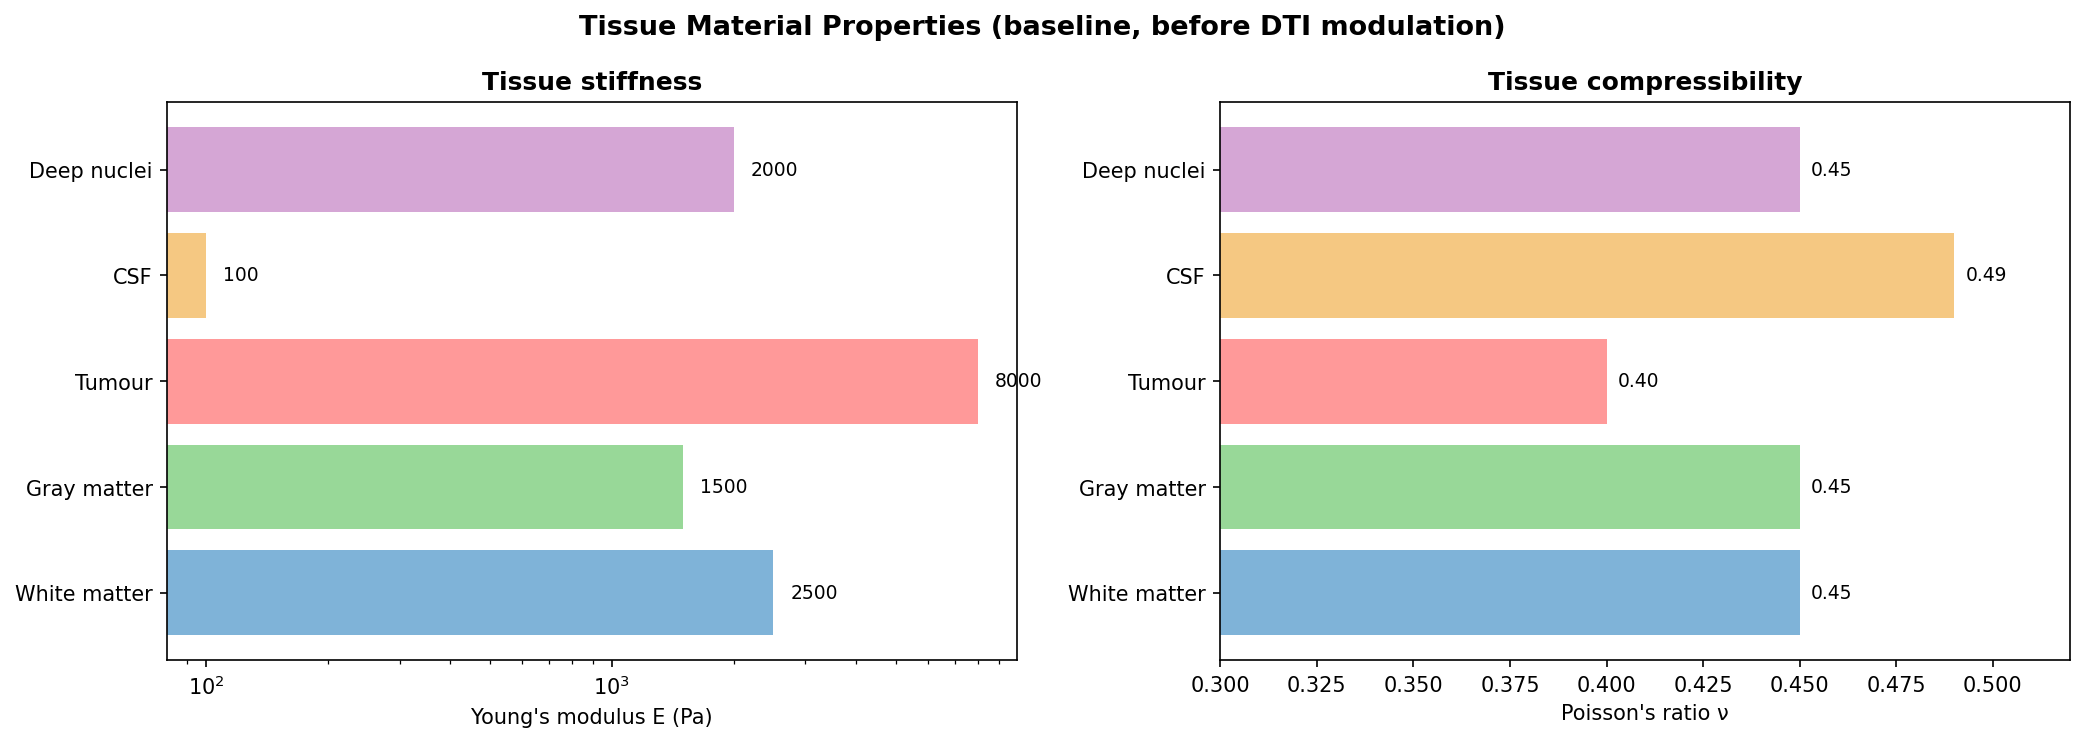

In [85]:
tissue_props = {
    'White matter':  {'E': 2500.0, 'nu': 0.45},
    'Gray matter':   {'E': 1500.0, 'nu': 0.45},
    'Tumour':        {'E': 8000.0, 'nu': 0.40},
    'CSF':           {'E':  100.0, 'nu': 0.49},
    'Deep nuclei':   {'E': 2000.0, 'nu': 0.45},
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Tissue Material Properties (baseline, before DTI modulation)',
             fontsize=13, fontweight='bold')

tissues = list(tissue_props.keys())
colors_t = ['#7FB3D8', '#98D898', '#FF9999', '#F5C882', '#D5A6D5']

E_vals = [tissue_props[t]['E'] for t in tissues]
axes[0].barh(tissues, E_vals, color=colors_t)
axes[0].set_xlabel("Young's modulus E (Pa)")
axes[0].set_title('Tissue stiffness', fontweight='bold')
axes[0].set_xscale('log')
for i, e in enumerate(E_vals):
    axes[0].text(e * 1.1, i, f'{e:.0f}', va='center', fontsize=9)

nu_vals = [tissue_props[t]['nu'] for t in tissues]
axes[1].barh(tissues, nu_vals, color=colors_t)
axes[1].set_xlabel("Poisson's ratio \u03bd")
axes[1].set_title('Tissue compressibility', fontweight='bold')
axes[1].set_xlim(0.3, 0.52)
for i, n in enumerate(nu_vals):
    axes[1].text(n + 0.003, i, f'{n:.2f}', va='center', fontsize=9)

plt.tight_layout()
fig.savefig(FIG_DIR / 'figC04_04_material_properties.png', bbox_inches='tight')
plt.show()

---
## Summary

In this notebook we have:

- Reviewed the physics of diffusion MRI and the diffusion tensor
- Loaded and visualised pipeline-computed DTI scalar maps (FA, MD, AD, RD)
- Loaded structural connectivity matrices (pre-op and post-op)
- Identified tractography files for interactive freeview visualisation
- Connected DTI metrics to material properties for the FEM simulation

### Key takeaways for the digital twin

- **FA and MD** inform heterogeneous material properties (NB\_C06)
- **SC matrix** is the substrate for neural dynamics (NB\_C07)
- **SC disruption** (pre-op vs post-op) is the predicted consequence of surgery
- **Tractography** provides visual confirmation of which fibre bundles
  pass through the tumour region

---

## References

- Basser PJ, Pierpaoli C (1996). Microstructural and physiological features of tissues elucidated by quantitative diffusion tensor MRI. *J Magn Reson B* 111:209--219.
- Le Bihan D et al. (2001). Diffusion tensor imaging: concepts and applications. *J Magn Reson Imaging* 13:534--546.
- Smith RE et al. (2015). SIFT2: Enabling dense quantitative assessment of brain white matter connectivity. *NeuroImage* 119:338--351.
- Tournier JD et al. (2019). MRtrix3: A fast, flexible and open software framework for medical image processing and visualisation. *NeuroImage* 202:116137.

---

**Next:** [NB\_C05](NB_C05_Resting_State_fMRI.ipynb) -- Resting-state fMRI, hemodynamics, and functional connectivity